<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/RBM_AdversarialDefence_Kehoe2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Restricted Boltzmann machines as an adversarial defence: Kehoe et al. (2021) step by step

This notebook re-implements, runs and checks the method of

> Aidan Kehoe, Peter Wittek, Yanbo Xue and Alejandro Pozas-Kerstjens,
> "Defence against adversarial attacks using classical and quantum-enhanced Boltzmann machines",
> *Machine Learning: Science and Technology* (2021), https://doi.org/10.1088/2632-2153/abf834 (arXiv:2012.11619).

**What the notebook does.** Neural-network classifiers are fooled by tiny, tailored changes of the input ("adversarial examples"). The paper asks whether a
*generative* model is harder to fool. It trains a **restricted Boltzmann machine (RBM)** on the joint vector *(image, label)* and classifies an image by asking which label gives the
lowest *free energy*. The RBM is trained either with the classical heuristic **persistent contrastive divergence (PCD)** or with samples from a **D-Wave 2000Q quantum annealer**.
Both are attacked with FGSM, DeepFool and Carlini-Wagner and compared with an adversarially trained CNN, feature squeezing and spatial smoothing (the paper's Tables 1 and 2).

**Important substitutions (all listed in the table below).** No annealer is available here, so the D-Wave sampler is replaced by a *classical simulated annealer* in Ising form
(thermal samples, no tunnelling; it is called "QRBM-sim" below and says nothing about quantum advantage). The fine-tuned ResNet18 is replaced by a small CNN, and the foolbox attacks are
re-written in PyTorch. Because the paper only attacks the classifier on the (defended) test images, an **adaptive attacker** (BPDA through the pre-processing defences, PGD, black-box SPSA,
budget sweeps) is added to find out whether the reported robustness is real or comes from useless gradients ("gradient masking").

**How to run it.** Open it in Colab (badge above), choose a CPU runtime and *Runtime -> Run all*. The outputs stored in this file come from **`FAST_MODE = True`** (reduced budgets,
about 25 minutes on one CPU thread of a shared Windows PC). `FAST_MODE = False` switches to the paper's PCD batch size 10 and chain length 50, more annealer updates, three seeds, 1 000
attacked images and longer attacks; those budgets are written into the configuration cell, but **that path was not executed for this file** (its run time on one CPU thread is estimated at two
hours or more), so no number in this notebook comes from it. MNIST is downloaded inside the notebook (Hugging Face mirror `ylecun/mnist`, fallback OpenML). It is public: no token is needed; if
Hugging Face rate-limits you, put your own token in Colab Secrets as `HF_TOKEN` (the notebook reads it from there or from the environment and never prints it).

**What you get at the end.** Re-drawn Tables 1 and 2 with this notebook's accuracies next to the paper's, one verdict per claim (tolerance 2 accuracy points), the results of the adaptive attack and of
the gradient-masking checks, a classical baseline on identical inputs, and a critical reading of the paper.

**Headline of the stored run.** The paper's central numbers (RBM 81-87 % accuracy under attack, far above every baseline) are **not reproduced**: with attack budgets fixed in advance
(FGSM L-infinity 0.3; DeepFool / Carlini-Wagner L2 2.0 on 28x28), our RBM keeps 14 / 28 / 20 % (FGSM / DeepFool / C&W) on 28x28 and adaptive PGD attacks reduce it to 5 % (cross-entropy loss) and 2 % (margin loss).
Of 27 numeric table cells, 1 is within 2 points, 8 are higher than the paper's and 18 are lower; none of the paper's qualitative rankings of the RBM and the annealer-trained RBM holds in this setup.
The sections below give the evidence and the many reasons why this is a comparison of two different experimental set-ups (unreported budgets and training length, a different backbone and attack code, a simulated annealer).

## The paper in one page

**Problem.** Discriminative networks trained by back-propagation are easy to fool with an imperceptible perturbation of the input. Defences (adversarial training, input
pre-processing) are usually broken soon after they are published. The authors argue that a *generative* model, which learns the whole data distribution, should be harder to fool.

**Decision.** For a test image, output the label that the model considers most probable (non-targeted attacks: the attacker only wants *any* wrong label).

**Method.** Train an RBM with energy `E(x, h) = -b.x - c.h - x^T W h` (binary units) on the concatenation of the image `x` and its one-hot label (Eq. 6). The classifier is the
free-energy rule `y(x) = argmin_l F(x, l)` with `F(x) = -b.x - sum_j log(1 + exp(c_j + (W^T x)_j))` (Eqs. 7 and 10). Training maximises the log-likelihood; its gradient is
*positive phase - negative phase* (Eq. 5), and the negative phase (an expectation over the model distribution) is the hard part. Two ways of estimating it:
1. **Classical:** persistent contrastive divergence, batch 10, `k = 50` Gibbs steps, 40 hidden units, Adam with learning rate 0.01, no regularisation (ebm-torch).
2. **"Quantum-enhanced":** draw 500 samples of the model's Boltzmann distribution from a **D-Wave 2000Q** annealer (20 microsecond anneal, 5 spin-reversal transforms, hand-tuned
   rescaling for the effective temperature, minor-embedding of the RBM on the Chimera graph), with a positive-phase batch of 1000; start from an RBM pre-trained classically for 100 epochs.

**Data.** MNIST, in two versions: the original 28x28 grey images (Table 1) and a 7x7 *binary* version small enough to embed on the annealer (Table 2).

**Attacks and baselines.** White-box, non-targeted FGSM, DeepFool and Carlini-Wagner (foolbox). Baselines: adversarial training, feature squeezing, spatial smoothing, each with a
fine-tuned ResNet18. Reported: the percentage of adversarial test images that the classifier still gets right.

**Claims to check.**
* Table 1 (28x28): adversarial training 13.4 / 12.8 / 72.0 %, feature squeezing 20.2 / 19.1 / 78.5 %, spatial smoothing 18.5 / 19.7 / 45.8 %, **RBM 81.2 / 83.4 / 83.2 %** (FGSM / DeepFool / Carlini-Wagner).
* Table 2 (7x7 binary): adversarial training 19.4 / 21.0 / 48.2 %, feature squeezing 28.0 / 26.6 / 77.2 %, spatial smoothing 14.7 / 13.7 / 22.0 %, **RBM 87.2 / 84.5 / 85.7 %**, **QRBM 84.5 / 85.2 / 82.9 %**.
* The RBM beats every baseline under every attack (gains of 4.62 to 72.41 points); the annealer-trained RBM is on par with the classical RBM and better under DeepFool.
* The paper reports no clean accuracy, no attack budgets, no number of epochs, no seeds and no adaptive attack.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST 60 000 / 10 000, 28x28 grey; 7x7 binary version | same MNIST; 7x7 = 4x4 average pooling then threshold 0.15 (`BIN_THRESH`; not specified in the paper, picked on the validation split by a logistic-regression check, see the cell after the data loader). Training subsets: 10 000 images for the RBMs and 10 000 (FAST) / 30 000 (full) for the CNNs; the last 2 000 training images are only used to watch training; the attacked test set is a fixed random subset of 300 (FAST) / 1 000 (full) test images, clean accuracy uses all 10 000 |
| RBM | 40 hidden units, lr 0.01, Adam, no regularisation, batch 10, `k = 50` (PCD) | same sizes and optimiser in the full run; FAST uses batch 20 and `k = 2` so that it finishes quickly. Weights initialised N(0, 0.01), zero biases; label units are sampled as independent Bernoulli units (not forced one-hot); positive phase uses grey values in [0, 1] as unit probabilities. Epochs are not given: 14 (FAST) / 4 (full) here |
| Classification | label with the lowest free energy | same (Eq. 10, evaluated for all 10 labels; `softmax(-F)` is the conditional `p(label | x)`, used as the loss of the attacks) |
| Quantum sampler | D-Wave 2000Q, 500 samples, 20 microsecond anneal, 5 spin-reversal transforms, hand-rescaled temperature, Chimera embedding, 100 pre-training epochs | **classical simulated annealer** (annealed block-Gibbs sweeps in spin form, `QA_SWEEPS = 20`), 500 samples per update split over 5 random spin-reversal gauges, effective inverse temperature `BETA_EFF = 1`, 1 % Gaussian control error on `h`, `J`; positive batch 1000. Pre-training 3 (FAST) / 2 (full) PCD epochs (not 100), then 1 000 (FAST) / 2 000 annealer updates. **No quantum effect is simulated, no embedding is needed** (the sampler is not hardware-sparse) |
| Backbone of the baselines | ResNet18, fine-tuned | small CNN trained from scratch (conv5-16, conv5-32, FC128 for 28x28; two conv3 + FC64 for 7x7) |
| Adversarial training | clean + adversarial mix | each batch mixed 1:1 with its own FGSM examples (eps 0.3) |
| Feature squeezing / spatial smoothing | colour bit-depth reduction / median filter (Xu et al.) | 1-bit depth / 2x2 median filter, the settings of Xu et al. for MNIST |
| Attacks | foolbox FGSM, DeepFool, Carlini-Wagner; budgets and settings not given | own PyTorch implementations. FGSM L-infinity 0.3; DeepFool (50 steps, overshoot 0.02, foolbox defaults) and Carlini-Wagner (box-clipped, reduced steps and binary search) clipped to an L2 ball of 2.0 on 28x28 and 0.5 on 7x7 (same budget per square-root of the dimension). Budgets were fixed before any result was seen |
| Metric | share of adversarial test images still classified correctly | same, counted over all attacked images (a clean mistake counts as an error) |
| Protocol | defence applied to train and test data, attacks built on the defended test images, adversarials fed to the classifier | **P1 = exactly that** (used for the verdicts). **P2 = adaptive:** the attacker works on the raw image through the whole pipeline (BPDA through squeezing and smoothing) - same as P1 for adversarial training and the RBM, which have no pre-processing |
| Seeds, repeats | not stated | `SEED = 42`; the 7x7 RBM and QRBM-sim are retrained with 2 (FAST) / 3 (full) seeds |
| Classical baseline on identical inputs | CNNs only | CNN family plus a capacity-matched back-propagation twin of the RBM (784-40-10 sigmoid MLP) and logistic regression / random forest / RBF-SVC |

Every choice is marked `# CHOICE:` in the code.

## 0. Setup

The next cells install the few helper packages that Colab might lack, collect **every tunable constant in one configuration cell** (`FAST_MODE`, sizes, budgets, attack settings,
seeds), and import the libraries with their versions printed. Everything random is seeded (Python, NumPy, PyTorch; the Gibbs chains, the annealer and the attacks draw from the seeded
PyTorch generator), so a rerun gives the same numbers.

In [1]:
# Versions used for this notebook (October 2026): Python 3.12, torch 2.x, numpy 2.x, pandas 2.x, scikit-learn 1.8, matplotlib 3.x.
# Colab already ships all of them. Only the Hugging Face / parquet helpers are installed when missing; a prepared environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pyarrow", "huggingface_hub", "PIL") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q pyarrow huggingface_hub pillow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pyarrow / huggingface_hub / pillow already present; skipping pip install.")

pyarrow / huggingface_hub / pillow already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE   = True          # True: class demo with reduced budgets (tens of minutes on one busy CPU thread). False: the larger run with the paper's PCD settings (hours).
SEED        = 42            # CHOICE: the paper gives no seed
N_THREADS   = 1             # CHOICE: CPU threads for PyTorch (all models are small)
DATA_DIR    = "qc326_data"  # downloaded MNIST is cached here (never inside a git repository)
IBM_TOKEN   = ""            # unused: the paper needs a D-Wave annealer, not a gate-based device; kept for the project template

# ---- data (paper: MNIST 60 000 train / 10 000 test; 28x28 grey and 7x7 binary) ----
N_TRAIN_CLF = 10_000 if FAST_MODE else 30_000   # CHOICE: training images for the CNN baselines (paper: all 60 000)
N_TRAIN_RBM = 10_000                           # CHOICE: training images for the RBMs (long persistent chains are slow on one CPU thread)
N_VAL       = 2_000                             # last images of the official training set, only used to monitor training (never the test set)
N_ATTACK    = 300 if FAST_MODE else 1_000       # CHOICE: test images that are attacked (paper: all 10 000); clean accuracy always uses all 10 000
BIN_THRESH  = 0.15                              # CHOICE: 7x7 images = 4x4 average pooling, then pixel >= 0.15 -> 1 (the paper does not say how; threshold picked on the validation split, see below)

# ---- RBM (paper: 40 hidden units, lr 0.01, Adam, PCD, batch 10, k = 50 chain steps) ----
N_HIDDEN    = 40
LR_RBM      = 0.01
PCD_BATCH, PCD_K = (20, 2) if FAST_MODE else (10, 50)   # FAST_MODE trades batch/chain length for speed; the full run uses the paper's 10 / 50
RBM_EPOCHS_28 = 14 if FAST_MODE else 4      # CHOICE: epochs are not given in the paper
RBM_EPOCHS_7  = 14 if FAST_MODE else 4
N_SEEDS_7     = 2 if FAST_MODE else 3      # independent RBM / QRBM-sim runs on the 7x7 data (the first one is the main model)

# ---- simulated annealer standing in for the D-Wave 2000Q (paper: batch 1000, 500 samples, 20 us anneal, 5 spin-reversal transforms) ----
QA_PRETRAIN_EPOCHS = 3 if FAST_MODE else 2     # classical PCD pre-training before the sampler takes over (paper: 100 epochs)
QA_UPDATES  = 1_000 if FAST_MODE else 2_000      # parameter updates with sampler-based negative phase
QA_BATCH    = 1000                              # positive-phase batch (paper)
QA_SAMPLES  = 500                               # negative-phase samples per update (paper)
QA_SWEEPS   = 20                                # CHOICE: annealing sweeps standing in for the 20 us anneal
N_GAUGES    = 5                                 # spin-reversal transforms per update (paper)
BETA_EFF    = 1.0                               # CHOICE: effective inverse temperature at the end of the anneal (the paper rescales by hand)
ICE_SIGMA   = 0.01                              # CHOICE: relative Gaussian control error on h and J (integrated control errors of a real chip)

# ---- classical CNN baselines (paper: ResNet18 fine-tuned; here a small CNN trained from scratch) ----
CNN_EPOCHS  = 3 if FAST_MODE else 5
CNN_BATCH, CNN_LR = 128, 1e-3

# ---- attacks (paper: foolbox FGSM, DeepFool, Carlini-Wagner; budgets not given) ----
EPS_LINF    = 0.3                                # CHOICE: FGSM budget (the usual MNIST L-infinity budget), chosen before looking at any result
EPS_L2_28   = 2.0                                # CHOICE: L2 budget for DeepFool and Carlini-Wagner on 28x28 (the usual MNIST L2 budget)
EPS_L2_7    = EPS_L2_28 * (49 / 784) ** 0.5      # CHOICE: same budget per sqrt(dimension) for the 7x7 images (= 0.5)
DF_STEPS, DF_OVERSHOOT = (30 if FAST_MODE else 50), 0.02   # foolbox defaults are 50 steps, overshoot 0.02
CW_STEPS    = 30 if FAST_MODE else 100           # CHOICE: foolbox uses 10 000 steps; reduced for CPU time
CW_BSTEPS   = 2 if FAST_MODE else 5              # binary-search steps over the trade-off constant (foolbox: 9)
CW_C0, CW_LR = 1.0, 0.05                          # CHOICE: initial constant and Adam step size
PGD_STEPS   = 20 if FAST_MODE else 40            # iterative L-infinity attack used for the gradient-masking checks
PGD_SWEEP_STEPS = 10                             # CHOICE: shorter PGD for the budget sweep
SPSA_STEPS, SPSA_SAMPLES, SPSA_DELTA = (8, 16, 0.05) if FAST_MODE else (15, 32, 0.05)
EPS_SWEEP   = [0.0, 0.1, 0.2, 0.3, 0.5, 1.0] if FAST_MODE else [0.0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0]
TOL_POINTS  = 2.0                                # verdict tolerance (accuracy points) when comparing with the paper

In [3]:
import os, io, time, math, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
torch.set_num_threads(N_THREADS)
os.makedirs(DATA_DIR, exist_ok=True)

def set_seed(s):
    """Fix every random number generator used below (python, numpy, torch)."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

T0 = time.time()
T0 = time.time()
set_seed(SEED)
RNG = np.random.default_rng(SEED)
print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| RBM epochs 28x28 / 7x7:", RBM_EPOCHS_28, "/", RBM_EPOCHS_7, "| PCD batch/k:", PCD_BATCH, PCD_K,
      "| attacked test images:", N_ATTACK)

torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = True | RBM epochs 28x28 / 7x7: 14 / 14 | PCD batch/k: 20 2 | attacked test images: 300


## 1. Data: MNIST at two resolutions

MNIST is downloaded from the public Hugging Face mirror `ylecun/mnist` (parquet with PNG bytes; fallback OpenML), decoded once and cached in `DATA_DIR`.
Pixels are scaled to [0, 1] (a fixed rule, nothing is fitted). The paper's second data set is built from the same digits: 4x4 average pooling to 7x7, then a threshold, which gives the
binary 7x7 images used for the annealer. Splits are fixed and disjoint: the first `N_TRAIN_*` training images fit the models, the last `N_VAL` training images only monitor training, the official
test set is used only for evaluation. No hyper-parameter was tuned on any split (all settings are fixed in the configuration cell).

In [4]:
from PIL import Image

# MNIST is public (no gate). The optional token is only used if the reader's Hugging Face account is rate-limited.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def load_mnist():
    """Return (Xtr, ytr, Xte, yte): 60 000 / 10 000 uint8 28x28 images with digit labels, cached in DATA_DIR."""
    cache = os.path.join(DATA_DIR, "mnist_28.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["Xtr"], z["ytr"], z["Xte"], z["yte"]
    try:
        from huggingface_hub import hf_hub_download
        parts = []
        for split in ("train", "test"):
            p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                                cache_dir=DATA_DIR, token=HF_TOKEN)
            df = pd.read_parquet(p)
            X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
            parts.append((X, df["label"].to_numpy().astype(int)))
        (Xtr, ytr), (Xte, yte) = parts
        print("MNIST downloaded from Hugging Face (ylecun/mnist)")
    except Exception as e:                           # fallback: OpenML through scikit-learn (70 000 images, first 60 000 = train)
        from sklearn.datasets import fetch_openml
        print(f"Hugging Face failed ({type(e).__name__}); falling back to OpenML mnist_784")
        d = fetch_openml("mnist_784", version=1, as_frame=False, data_home=DATA_DIR, parser="liac-arff")
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        Xtr, ytr, Xte, yte = X[:60000], y[:60000], X[60000:], y[60000:]
    np.savez_compressed(cache, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
    return Xtr, ytr, Xte, yte

Xtr_u8, ytr_np, Xte_u8, yte_np = load_mnist()

def to_flat28(X):                 # [0,1] floats, one row of 784 pixels per image
    return torch.tensor(X.reshape(len(X), -1) / 255.0, dtype=torch.float32)

def to_flat7(X):                  # CHOICE: 4x4 average pooling -> 7x7, then binarise (the paper only says "downscaled to 7x7 and binarized")
    p = (X.reshape(len(X), 7, 4, 7, 4) / 255.0).mean(axis=(2, 4))
    return torch.tensor((p >= BIN_THRESH).reshape(len(X), -1), dtype=torch.float32)

# Fixed, disjoint splits of the official training set: [0, N_TRAIN) for fitting, the last N_VAL images only to monitor training.
tr_idx_clf = np.arange(N_TRAIN_CLF); tr_idx_rbm = np.arange(N_TRAIN_RBM); val_idx = np.arange(60000 - N_VAL, 60000)
assert max(tr_idx_clf.max(), tr_idx_rbm.max()) < val_idx.min()

DS = {}
for side, conv in ((28, to_flat28), (7, to_flat7)):
    DS[side] = dict(
        Xtr=conv(Xtr_u8), ytr=torch.tensor(ytr_np), Xte=conv(Xte_u8), yte=torch.tensor(yte_np),
        Xva=conv(Xtr_u8[val_idx]), yva=torch.tensor(ytr_np[val_idx]))
att_idx = torch.tensor(np.random.default_rng(SEED).permutation(10_000)[:N_ATTACK])   # the attacked test images (fixed)
for side in DS:
    DS[side]["Xatt"], DS[side]["yatt"] = DS[side]["Xte"][att_idx], DS[side]["yte"][att_idx]
    print(f"{side}x{side}: train {tuple(DS[side]['Xtr'].shape)}  test {tuple(DS[side]['Xte'].shape)}  attacked {N_ATTACK}  value range "
          f"[{DS[side]['Xtr'].min():.0f}, {DS[side]['Xtr'].max():.0f}]  distinct values in 7x7: "
          f"{DS[7]['Xtr'].unique().tolist() if side == 7 else '-'}")

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

MNIST downloaded from Hugging Face (ylecun/mnist)


28x28: train (60000, 784)  test (10000, 784)  attacked 300  value range [0, 1]  distinct values in 7x7: -


7x7: train (60000, 49)  test (10000, 49)  attacked 300  value range [0, 1]  distinct values in 7x7: [0.0, 1.0]


In [5]:
# CHOICE check on the validation split only: how much information survives the binarisation of the 7x7 images? A logistic regression is fitted on
# training images and scored on the validation images (never the test set) for several thresholds; BIN_THRESH in the configuration cell was set from this table.
rows = []
tr5 = tr_idx_clf[:5000]
for th in (0.05, 0.15, 0.3, 0.5):
    ptr = ((Xtr_u8[tr5].reshape(-1, 7, 4, 7, 4) / 255.0).mean(axis=(2, 4)) >= th).reshape(len(tr5), -1)
    pva = ((Xtr_u8[val_idx].reshape(-1, 7, 4, 7, 4) / 255.0).mean(axis=(2, 4)) >= th).reshape(len(val_idx), -1)
    lr_ = LogisticRegression(max_iter=200).fit(ptr, ytr_np[tr5])
    rows.append(dict(threshold=th, share_of_pixels_set=round(ptr.mean(), 3), validation_accuracy=round(lr_.score(pva, ytr_np[val_idx]), 4), chosen="<-" if th == BIN_THRESH else ""))
print(pd.DataFrame(rows).to_string(index=False))

 threshold  share_of_pixels_set  validation_accuracy chosen
      0.05                0.320               0.8210       
      0.15                0.261               0.8380     <-
      0.30                0.195               0.8290       
      0.50                0.114               0.7165       


## Dataset Exploration and Visualisation

Everything below shows the *real* data used in this notebook: shapes, feature names, original labels and class counts, the class distribution, example images, and a 2-D
projection of real images coloured by their ground-truth digit.

MNIST (official split): train (60000, 28, 28) test (10000, 28, 28) dtype uint8
28x28 features: 784 pixel intensities ['pixel_0', 'pixel_1', 'pixel_2'] ... ['pixel_782', 'pixel_783'] (row-major grid, integers 0-255 -> scaled to [0, 1])
7x7 features  : 49 pixels ['cell_0', 'cell_1', 'cell_2'] ... (4x4 mean of the 28x28 grid, then binarised at 0.15 )
original labels: digits 0-9 (ground truth, never altered or generated)
 digit  train (60 000)  test (10 000)  used for CNN training  used for RBM training  attacked test images
     0            5923            980                   1001                   1001                    27
     1            6742           1135                   1127                   1127                    45
     2            5958           1032                    991                    991                    22
     3            6131           1010                   1032                   1032                    24
     4            5842            982            

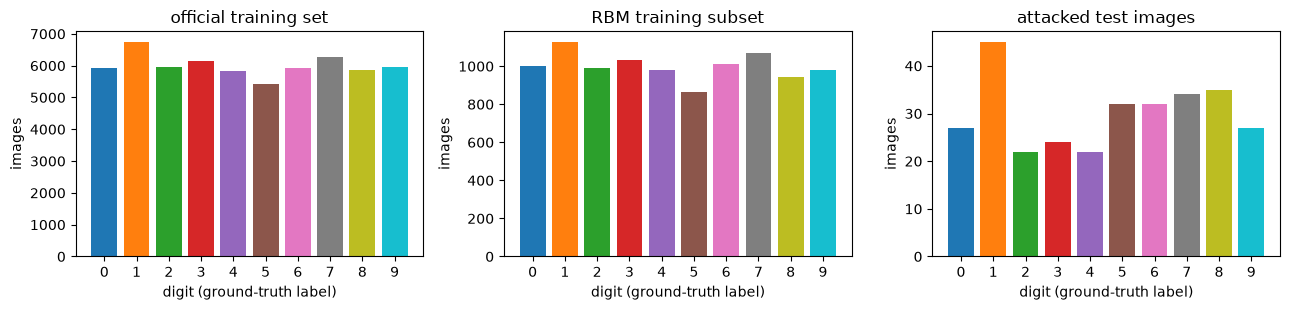

In [6]:
# Shapes, feature names and original labels of the data actually used.
names = [f"pixel_{i}" for i in range(784)]
print("MNIST (official split): train", Xtr_u8.shape, "test", Xte_u8.shape, "dtype", Xtr_u8.dtype)
print("28x28 features:", len(names), "pixel intensities", names[:3], "...", names[-2:], "(row-major grid, integers 0-255 -> scaled to [0, 1])")
print("7x7 features  :", 49, "pixels", [f"cell_{i}" for i in range(3)], "... (4x4 mean of the 28x28 grid, then binarised at", BIN_THRESH, ")")
print("original labels: digits 0-9 (ground truth, never altered or generated)")
cnt = pd.DataFrame({"digit": range(10), "train (60 000)": np.bincount(ytr_np, minlength=10), "test (10 000)": np.bincount(yte_np, minlength=10)})
cnt["used for CNN training"] = np.bincount(ytr_np[tr_idx_clf], minlength=10)
cnt["used for RBM training"] = np.bincount(ytr_np[tr_idx_rbm], minlength=10)
cnt["attacked test images"] = np.bincount(DS[28]["yatt"].numpy(), minlength=10)
print(cnt.to_string(index=False))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (col, ttl) in zip(axs, [("train (60 000)", "official training set"), ("used for RBM training", "RBM training subset"), ("attacked test images", "attacked test images")]):
    ax.bar(cnt["digit"], cnt[col], color=plt.cm.tab10(np.arange(10))); ax.set_xticks(range(10)); ax.set_xlabel("digit (ground-truth label)"); ax.set_ylabel("images"); ax.set_title(ttl)
plt.tight_layout(); plt.show()

Real digits, six per class: left the 28x28 grey images, right the binarised 7x7 version of the *same* images. The 7x7 version keeps the coarse shape but loses stroke detail, which is why
every model is less accurate on it.

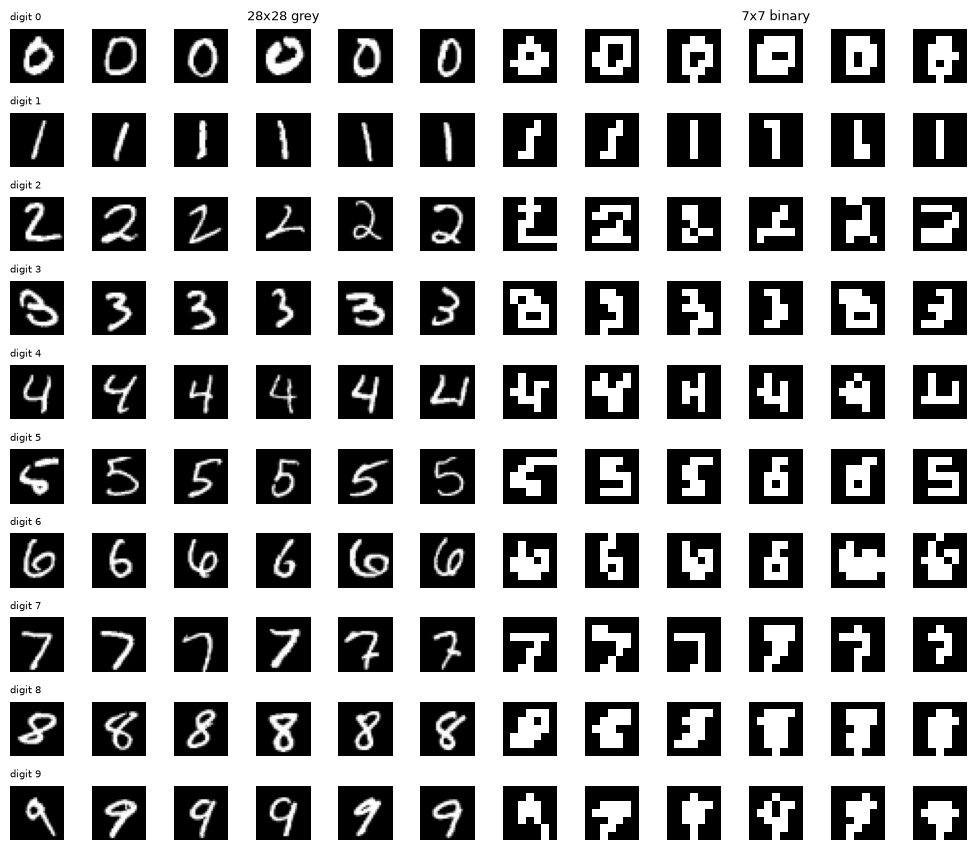

In [7]:
# Real images, 6 per class: the 28x28 grey images and the binarised 7x7 version of the same digits.
fig, axs = plt.subplots(10, 12, figsize=(10, 8.6))
for d in range(10):
    ids = np.where(yte_np == d)[0][:6]
    for j, i in enumerate(ids):
        axs[d, j].imshow(Xte_u8[i], cmap="gray", vmin=0, vmax=255); axs[d, j].axis("off")
        axs[d, 6 + j].imshow(DS[7]["Xte"][i].view(7, 7), cmap="gray", vmin=0, vmax=1); axs[d, 6 + j].axis("off")
    axs[d, 0].set_title(f"digit {d}", fontsize=7, loc="left")
axs[0, 3].set_title("28x28 grey", fontsize=9); axs[0, 9].set_title("7x7 binary", fontsize=9)
plt.tight_layout(); plt.show()

The scatter plots place real images by their two leading principal components (PCA fitted on the training split only; test images are projected with that fit), coloured by the digit label.
The classes overlap heavily in two dimensions, which is expected for MNIST: a classifier needs all 784 (or 49) dimensions. This paper does not use angle encoding, so there is no
[0, pi]-scaled copy of this plot.

28x28: explained variance of the two PCA axes = [0.102 0.072]
7x7: explained variance of the two PCA axes = [0.145 0.1  ]


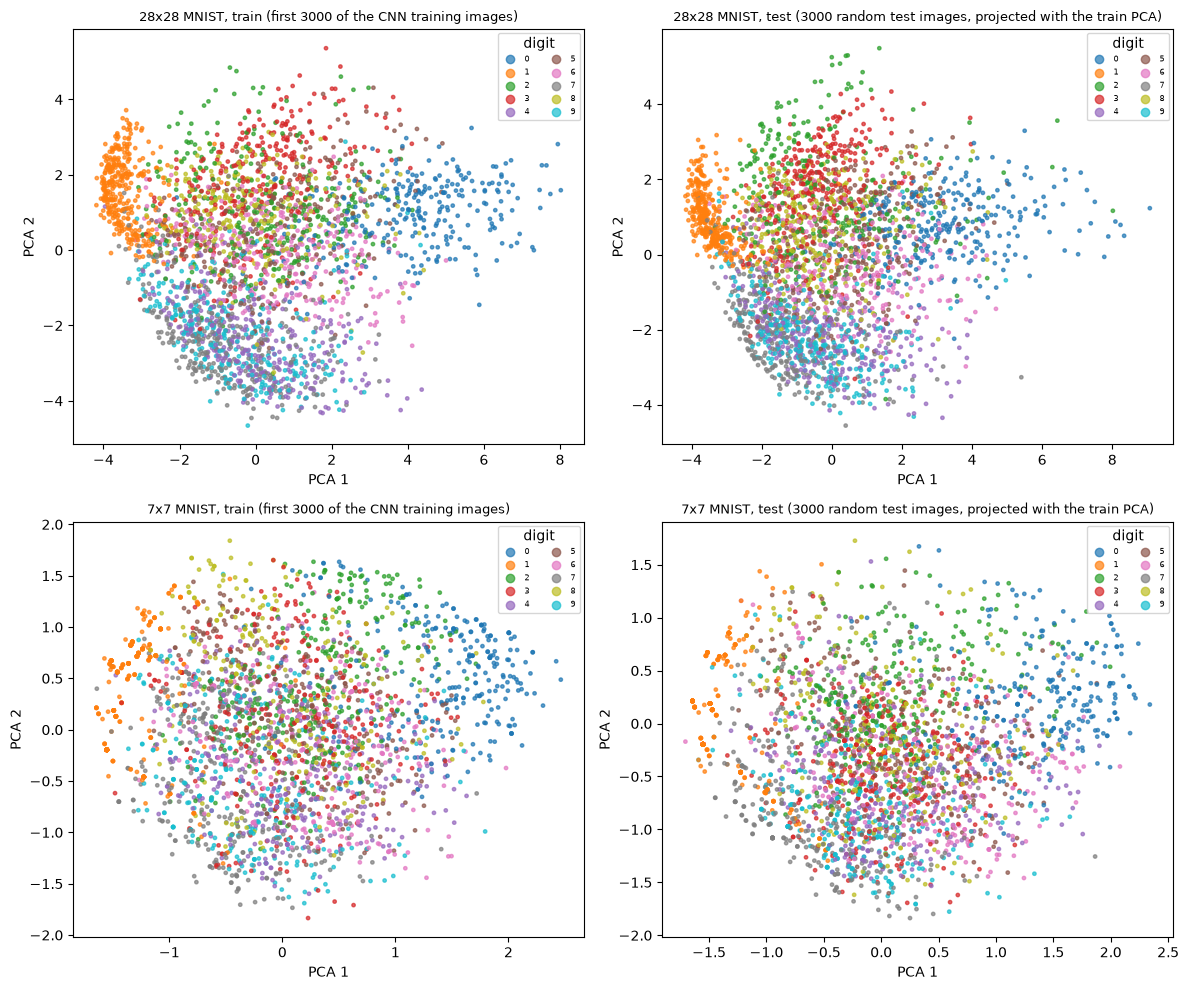

In [8]:
# 2-D scatter of REAL observations coloured by their ground-truth digit. PCA is fitted on the training split only; the test images are projected
# with the same transform. (Angle encoding / [0, pi] scaling is not used by this paper, so there is no second, scaled scatter.)
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
for r, side in enumerate((28, 7)):
    pca = PCA(n_components=2, random_state=SEED).fit(DS[side]["Xtr"][tr_idx_clf].numpy())
    for c, (nm, X, y) in enumerate((("train (first 3000 of the CNN training images)", DS[side]["Xtr"][:3000], DS[side]["ytr"][:3000]),
                                    ("test (3000 random test images, projected with the train PCA)", DS[side]["Xte"][:3000], DS[side]["yte"][:3000]))):
        Z = pca.transform(X.numpy()); ax = axs[r, c]
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=y.numpy(), cmap="tab10", s=6, alpha=0.7)
        ax.set_title(f"{side}x{side} MNIST, {nm}", fontsize=9); ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2")
        ax.legend(*sc.legend_elements(), title="digit", fontsize=6, ncol=2, loc="best")
    print(f"{side}x{side}: explained variance of the two PCA axes = {pca.explained_variance_ratio_.round(3)}")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

NOT_APPLICABLE: the paper trains a Boltzmann machine whose quantum part is a D-Wave annealer (an analogue Ising Hamiltonian, Eq. 9), not a gate-based circuit; this notebook replaces it by a classical simulated annealer, so no quantum circuit is executed or drawn.

## 2. The RBM as a classifier (Eqs. 2-10)

**Model.** Visible units `v = (x, y)` are the pixels plus ten label units; there are 40 hidden units. The free energy `F(v)` of Eq. (7) is the hidden layer summed out analytically.
**Classification (Eq. 10).** For a test image `x` we compute `F(x, l)` for all ten labels `l` and output the one with the smallest value. `logits(x) = -F(x, .)` is differentiable in `x`, so the attacks can use its gradient directly.
**Training.** The gradient of the negative log-likelihood is *positive phase - negative phase* (Eq. 5/8). The positive phase is computed exactly from the data; the negative phase needs samples of the model.
*Persistent contrastive divergence* keeps a set of Markov chains alive between updates and advances them `k` block-Gibbs steps per update. Adam (lr 0.01) applies the gradient.

The cell after the implementation checks the maths on a tiny RBM where all `2^13` states can be enumerated: the closed-form free energy, the classification rule and the gradient are compared with brute force.

In [9]:
class RBMClassifier:
    """Restricted Boltzmann machine on the joint vector (x, one-hot label) with binary units, Eq. (6) of the paper.
    Trained generatively; classification = argmin over labels of the free energy of Eq. (7) / (10).
    All parameters live in one flat vector P (W, b, c are views of it), which makes the Adam update a handful of tensor operations."""
    def __init__(self, nx, nh=N_HIDDEN, ny=10, seed=SEED, init_std=0.01, dtype=torch.float32):
        g = torch.Generator().manual_seed(seed)
        self.nx, self.nh, self.ny = nx, nh, ny; nv = nx + ny
        self.P = torch.zeros(nv * nh + nv + nh, dtype=dtype); self.G = torch.zeros_like(self.P)
        self.W, self.b, self.c = self._views(self.P); self.gW, self.gb, self.gc = self._views(self.G)
        self.W.copy_(torch.randn(nv, nh, generator=g) * init_std)       # CHOICE: N(0, 0.01^2) initial weights, zero biases (not given)

    def _views(self, v):
        nv, nh = self.nx + self.ny, self.nh
        return v[:nv * nh].view(nv, nh), v[nv * nh:nv * nh + nv], v[nv * nh + nv:]

    def clone(self, dtype=None):
        m = RBMClassifier(self.nx, self.nh, self.ny, dtype=dtype or self.P.dtype); m.P.copy_(self.P); return m

    def free_energy(self, v):                    # Eq. (7): F(v) = -b.v - sum_j softplus(c_j + (W^T v)_j)
        return -(v @ self.b) - F.softplus(self.c + v @ self.W).sum(1)

    def logits(self, x):                          # differentiable in x: logit_l = -F(x, l), so softmax(logits) = p(l | x)
        Wx, Wl, bx, bl = self.W[:self.nx], self.W[self.nx:], self.b[:self.nx], self.b[self.nx:]
        pre = self.c + x @ Wx
        Fe = -(x @ bx)[:, None] - bl[None] - F.softplus(pre[:, None, :] + Wl[None]).sum(2)
        return -Fe

    def __call__(self, x): return self.logits(x)

class FlatAdam:
    """Adam (Kingma & Ba) on one flat parameter vector; the gradient is written into the machine's G vector."""
    def __init__(self, m, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m_, self.P, self.G, self.lr, self.b1, self.b2, self.eps, self.t = m, m.P, m.G, lr, b1, b2, eps, 0
        self.m, self.v = torch.zeros_like(m.P), torch.zeros_like(m.P)
    def step(self):
        self.t += 1; G = self.G
        self.m.mul_(self.b1).add_(G, alpha=1 - self.b1); self.v.mul_(self.b2).addcmul_(G, G, value=1 - self.b2)
        denom = (self.v / (1 - self.b2 ** self.t)).sqrt_().add_(self.eps)
        self.P.addcdiv_(self.m, denom, value=-self.lr / (1 - self.b1 ** self.t))

def bern(p, gen=None): return torch.bernoulli(p, generator=gen)

def sgd_step(m, opt, vp, vn, hp, hn):
    """Gradient of the negative log-likelihood, Eq. (5) / (8): -(positive phase - negative phase); then one Adam step."""
    m.gW.copy_(-(vp.T @ hp / vp.shape[0] - vn.T @ hn / vn.shape[0]))
    m.gb.copy_(-(vp.mean(0) - vn.mean(0))); m.gc.copy_(-(hp.mean(0) - hn.mean(0)))
    opt.step()

def with_labels(X, Y): return torch.cat([X, F.one_hot(Y, 10).float()], 1)

def val_acc(m, side):
    with torch.no_grad(): return (m.logits(DS[side]["Xva"]).argmax(1) == DS[side]["yva"]).float().mean().item()

def train_pcd(m, side, epochs, batch=PCD_BATCH, k=PCD_K, lr=LR_RBM, seed=SEED, tag="RBM", log=None):
    """Persistent contrastive divergence (paper: batch 10, k = 50, lr 0.01, Adam, no regularisation)."""
    set_seed(seed)
    X, Y = DS[side]["Xtr"][tr_idx_rbm], DS[side]["ytr"][tr_idx_rbm]
    V = with_labels(X, Y); N = len(V)
    opt = FlatAdam(m, lr)
    chains = V[torch.randperm(N)[:batch]].clone()          # persistent fantasy particles
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(N); t0 = time.time()
        with torch.no_grad():
            for i in range(0, N - batch + 1, batch):
                vp = V[perm[i:i + batch]]
                hp = torch.sigmoid(torch.addmm(m.c, vp, m.W))     # positive phase: exact conditional of the hidden layer
                v = chains
                for _ in range(k):                                 # negative phase: k block-Gibbs steps from the persistent chains
                    h = bern(torch.sigmoid(torch.addmm(m.c, v, m.W))); v = bern(torch.sigmoid(torch.addmm(m.b, h, m.W.T)))
                chains = v
                sgd_step(m, opt, vp, v, hp, torch.sigmoid(torch.addmm(m.c, v, m.W)))
        hist.append(val_acc(m, side))
        if log: log(tag, ep + 1, hist[-1], time.time() - t0)
        if hasattr(m, "snapshots"): m.snapshots[ep + 1] = m.clone()
    return m, hist

In [10]:
# --- unit tests of the RBM maths on a tiny machine (8 visible = 6 "pixels" + 2 "labels", 5 hidden units) where everything can be enumerated ---
import itertools
def all_states(n): return torch.tensor(list(itertools.product([0., 1.], repeat=n)))

tiny = RBMClassifier(6, nh=5, ny=2, seed=1, init_std=1.0)
tiny.b.copy_(torch.randn(8) * 0.5); tiny.c.copy_(torch.randn(5) * 0.5)
V = all_states(8); H = all_states(5)
E = -(V @ tiny.b)[:, None] - (H @ tiny.c)[None] - V @ tiny.W @ H.T                    # Eq. (6) for all 2^13 (v, h) pairs
logZ = torch.logsumexp(-E.flatten(), 0)
F_enum = -torch.logsumexp(-E, 1)                                                     # Eq. (3): e^{-F(v)} = sum_h e^{-E(v,h)}
assert torch.allclose(F_enum, tiny.free_energy(V), atol=1e-4), "closed-form free energy (Eq. 7) disagrees with the enumeration"
# classification rule Eq. (10): p(label | x) from the enumerated joint equals softmax(-F(x, l))
X6 = all_states(6); lab = torch.eye(2)
joint = torch.stack([torch.exp(-tiny.free_energy(torch.cat([X6, lab[l].expand(64, 2)], 1)) - logZ) for l in range(2)], 1)
assert torch.allclose(joint / joint.sum(1, keepdim=True), torch.softmax(tiny.logits(X6), 1), atol=1e-4)
print("free energy (Eq. 7) and conditional p(label | x) agree with brute-force enumeration of all 2^13 states")

# exact gradient of the negative log-likelihood (Eq. 5) vs. autograd of the same enumerated likelihood
data = V[torch.randint(0, 256, (20,))]
p_params = [nn.Parameter(p.clone()) for p in (tiny.W, tiny.b, tiny.c)]
Eg = -(V @ p_params[1])[:, None] - (H @ p_params[2])[None] - V @ p_params[0] @ H.T
nll = -(torch.logsumexp(-Eg, 1)[torch.argmax((data[:, None, :] == V[None]).all(2).float(), 1)] - torch.logsumexp(-Eg.flatten(), 0)).mean()
nll.backward()
pv = torch.exp(-F_enum - logZ); hv = torch.sigmoid(tiny.c + V @ tiny.W); hd = torch.sigmoid(tiny.c + data @ tiny.W)
gW = -(data.T @ hd / 20 - (V * pv[:, None]).T @ hv)
print("exact positive-minus-negative phase gradient matches autograd of the exact NLL:", bool(torch.allclose(gW, p_params[0].grad, atol=1e-4)))

free energy (Eq. 7) and conditional p(label | x) agree with brute-force enumeration of all 2^13 states
exact positive-minus-negative phase gradient matches autograd of the exact NLL: True


## 3. The annealer stand-in (Sec. 3.2 and 4.3)

On the D-Wave chip the RBM becomes an Ising Hamiltonian over spins `+-1`; the chip returns samples that are (approximately) thermal at some effective temperature. Here a **classical simulated annealer**
does the same job: block-Gibbs sweeps whose inverse temperature is raised from 0.05 to the final `BETA_EFF` over `QA_SWEEPS` sweeps (the "anneal"). The pieces the paper describes are kept:
the binary-to-Ising conversion, **spin-reversal transforms** (a random gauge `s -> a*s`, `J -> a_i a_j J`, `h -> a h` that leaves every energy unchanged but averages out hardware biases),
**control errors** on `h` and `J`, and the effective temperature. What is *not* simulated: quantum fluctuations and Chimera embedding. A thermal annealer cannot show a quantum advantage;
the experiment only tests whether better negative-phase samples change robustness.

The check cell compares the sampler with the exact Boltzmann distribution of a small RBM (14 units, total-variation distance) and with plain Gibbs chains, and asserts that the gauge transformation and the Ising mapping leave energies unchanged.

In [11]:
# ----------------------------------------------------------------------------------------------------------------------------
# Annealer stand-in (CHOICE): the D-Wave 2000Q is replaced by a classical *simulated* annealer in spin (Ising) form.  It is a
# thermal sampler: there is no transverse field, so no quantum tunnelling is simulated.  Everything else that the paper describes
# is reproduced: Ising mapping, a finite anneal (QA_SWEEPS sweeps), an effective temperature BETA_EFF at the end of the anneal,
# spin-reversal transforms, control errors on h and J, and 500 samples per call.
# ----------------------------------------------------------------------------------------------------------------------------
def rbm_to_ising(W, b, c):
    """x = (1 + s)/2:  E(x, h) = -b.x - c.h - x^T W h  =  -hv.s - hh.t - s^T J t + const  with J = W/4, hv = b/2 + W1/4, hh = c/2 + W^T1/4."""
    return W / 4, b / 2 + W.sum(1) / 4, c / 2 + W.sum(0) / 4

def ising_energy(s, t, J, hv, hh): return -(s @ hv) - (t @ hh) - ((s @ J) * t).sum(1)

def anneal_sample(W, b, c, n, sweeps=QA_SWEEPS, beta=BETA_EFF, gauges=N_GAUGES, ice=ICE_SIGMA, gen=None):
    """Draw n samples (v, h in {0,1}) of the Boltzmann distribution exp(-beta E) with an annealed block-Gibbs sampler.
    The n samples are split over `gauges` random spin-reversal transforms (run in parallel as a batch); each gauge also gets its own control-error draw."""
    J0, hv0, hh0 = rbm_to_ising(W, b, c); nv, nh = W.shape; G = gauges; m = -(-n // G)
    scale = max(J0.abs().max().item(), hv0.abs().max().item(), hh0.abs().max().item(), 1e-9)
    av = (torch.randint(0, 2, (G, nv), generator=gen) * 2 - 1).float(); ah = (torch.randint(0, 2, (G, nh), generator=gen) * 2 - 1).float()
    J = av[:, :, None] * J0[None] * ah[:, None, :] + ice * scale * torch.randn((G, nv, nh), generator=gen)          # gauge transform + control error
    hv = av * hv0[None] + ice * scale * torch.randn((G, nv), generator=gen); hh = ah * hh0[None] + ice * scale * torch.randn((G, nh), generator=gen)
    s = (torch.randint(0, 2, (G, m, nv), generator=gen) * 2 - 1).float(); t = (torch.randint(0, 2, (G, m, nh), generator=gen) * 2 - 1).float()
    Jt = J.transpose(1, 2)
    for bt in beta * torch.logspace(math.log10(0.05), 0.0, sweeps):                                                # anneal: hot -> effective temperature
        t = torch.where(torch.rand((G, m, nh), generator=gen) < torch.sigmoid(2 * bt * (hh[:, None, :] + torch.bmm(s, J))), 1.0, -1.0)
        s = torch.where(torch.rand((G, m, nv), generator=gen) < torch.sigmoid(2 * bt * (hv[:, None, :] + torch.bmm(t, Jt))), 1.0, -1.0)
    v = ((s * av[:, None, :] + 1) / 2).reshape(G * m, nv)[:n]; h = ((t * ah[:, None, :] + 1) / 2).reshape(G * m, nh)[:n]   # undo the gauge, back to {0,1}
    return v, h

def train_qa(m, side, updates, batch=QA_BATCH, nsamp=QA_SAMPLES, lr=LR_RBM, seed=SEED, tag="QRBM-sim", log=None, log_every=50):
    """Negative phase from the annealer (paper), positive phase from a large batch (1000), Adam, lr 0.01."""
    set_seed(seed); gen = torch.Generator().manual_seed(seed)
    X, Y = DS[side]["Xtr"][tr_idx_rbm], DS[side]["ytr"][tr_idx_rbm]; V = with_labels(X, Y); N = len(V)
    opt = FlatAdam(m, lr); hist = []; t0 = time.time()
    with torch.no_grad():
        for u in range(updates):
            vp = V[torch.randint(0, N, (batch,), generator=gen)]
            hp = torch.sigmoid(torch.addmm(m.c, vp, m.W))
            vn, _ = anneal_sample(m.W, m.b, m.c, nsamp, gen=gen)
            sgd_step(m, opt, vp, vn, hp, torch.sigmoid(torch.addmm(m.c, vn, m.W)))     # hidden layer of the negative phase in expectation
            if (u + 1) % log_every == 0 or u + 1 == updates:
                hist.append((u + 1, val_acc(m, side)))
                if log: log(tag, u + 1, hist[-1][1], time.time() - t0)
    return m, hist

In [12]:
# --- validation of the sampler against the exact Boltzmann distribution of a small RBM (14 units, everything enumerable) ---
gen = torch.Generator().manual_seed(SEED)
rows = []
for scale in (0.5, 1.0, 2.0):                                      # stronger couplings = rougher energy landscape
    tr = RBMClassifier(6, nh=6, ny=2, seed=3, init_std=scale); tr.b.copy_(torch.randn(8, generator=gen) * 0.3); tr.c.copy_(torch.randn(6, generator=gen) * 0.3)
    Vs = all_states(8); Hs = all_states(6)
    E = -(Vs @ tr.b)[:, None] - (Hs @ tr.c)[None] - Vs @ tr.W @ Hs.T
    p_exact = torch.softmax(-tr.free_energy(Vs), 0)                  # exact marginal over the 256 visible states
    key = lambda v: (v * (2 ** torch.arange(7, -1, -1))).sum(1).long()
    def tv(samples): return 0.5 * (torch.bincount(key(samples), minlength=256).float() / len(samples) - p_exact).abs().sum().item()
    # gauge invariance: the spin-reversal transform must not change any energy
    J, hv_, hh_ = rbm_to_ising(tr.W, tr.b, tr.c); s0 = torch.randint(0, 2, (5, 8)).float() * 2 - 1; t0_ = torch.randint(0, 2, (5, 6)).float() * 2 - 1
    av = torch.randint(0, 2, (8,)).float() * 2 - 1; ah = torch.randint(0, 2, (6,)).float() * 2 - 1
    assert torch.allclose(ising_energy(s0, t0_, J, hv_, hh_), ising_energy(s0 * av, t0_ * ah, av[:, None] * J * ah[None], av * hv_, ah * hh_), atol=1e-5)
    # Ising mapping check: E_ising + const == binary energy for every sample
    sv = Vs[:5]; th = Hs[:5]; e_bin = -(sv @ tr.b) - (th @ tr.c) - ((sv @ tr.W) * th).sum(1)
    e_is = ising_energy(2 * sv - 1, 2 * th - 1, J, hv_, hh_); assert torch.allclose(e_bin - e_is, (e_bin - e_is)[0].expand(5), atol=1e-4)
    rows.append(dict(coupling_scale=scale, sampler="IDEAL: 20 000 exact i.i.d. samples (noise floor)", TV_distance_to_exact=tv(Vs[torch.multinomial(p_exact, 20_000, replacement=True, generator=gen)])))
    for sweeps in (2, 5, 20, 60):
        v, _ = anneal_sample(tr.W, tr.b, tr.c, 20_000, sweeps=sweeps, ice=0.0, gen=gen)
        rows.append(dict(coupling_scale=scale, sampler=f"annealed Gibbs, {sweeps} sweeps", TV_distance_to_exact=tv(v)))
    v, _ = anneal_sample(tr.W, tr.b, tr.c, 20_000, sweeps=QA_SWEEPS, ice=ICE_SIGMA, gen=gen)
    rows.append(dict(coupling_scale=scale, sampler=f"as used in training ({QA_SWEEPS} sweeps, {N_GAUGES} gauges, ICE {ICE_SIGMA})", TV_distance_to_exact=tv(v)))
    # plain Gibbs with k = 1 and k = 50 from a random start (what CD / PCD chains look like from scratch)
    for k in (1, 50):
        v = bern(torch.full((20_000, 8), 0.5), gen)
        for _ in range(k):
            h = bern(torch.sigmoid(tr.c + v @ tr.W), gen); v = bern(torch.sigmoid(tr.b + h @ tr.W.T), gen)
        rows.append(dict(coupling_scale=scale, sampler=f"block Gibbs from random start, k={k}", TV_distance_to_exact=tv(v)))
print("gauge invariance of the energies and the Ising mapping: OK")
print(pd.DataFrame(rows).pivot(index="sampler", columns="coupling_scale", values="TV_distance_to_exact").round(4).to_string())
print("(TV = total-variation distance to the exact distribution of the visible units; 0 is perfect, the first row is the noise floor of 20 000 perfect samples)")

gauge invariance of the energies and the Ising mapping: OK
coupling_scale                                          0.5     1.0     2.0
sampler                                                                    
IDEAL: 20 000 exact i.i.d. samples (noise floor)     0.0410  0.0289  0.0149
annealed Gibbs, 2 sweeps                             0.0567  0.1377  0.2598
annealed Gibbs, 20 sweeps                            0.0422  0.0346  0.0248
annealed Gibbs, 5 sweeps                             0.0477  0.0718  0.0924
annealed Gibbs, 60 sweeps                            0.0395  0.0331  0.0205
as used in training (20 sweeps, 5 gauges, ICE 0.01)  0.0446  0.0406  0.0329
block Gibbs from random start, k=1                   0.0625  0.1445  0.2755
block Gibbs from random start, k=50                  0.0387  0.0332  0.0150
(TV = total-variation distance to the exact distribution of the visible units; 0 is perfect, the first row is the noise floor of 20 000 perfect samples)


## 4. Classical baselines and baseline defences (Sec. 4.2)

* **CNN (undefended)**: the discriminative model every defence is built on. (CHOICE: a small CNN trained from scratch instead of the fine-tuned ResNet18.)
* **Adversarial training**: each batch is mixed 1:1 with FGSM examples crafted against the current network.
* **Feature squeezing**: pixel values rounded to 1 bit (training and test data both squeezed).
* **Spatial smoothing**: 2x2 median filter (training and test data both smoothed).
* **MLP-40**: an extra control. The same 40 hidden sigmoid units as the RBM, but trained discriminatively by back-propagation. If the RBM is more robust than this twin, the generative training is what matters; if not, the capacity is.

For the two pre-processing defences, the gradient-based attacks cannot differentiate through rounding or the median. An adaptive attacker uses **BPDA** (backward pass differentiable approximation, Athalye et al. 2018): the forward pass uses the real defence, the backward pass pretends it is the identity.

In [13]:
# ---------------- classical discriminative baselines (CHOICE: small CNN instead of the fine-tuned ResNet18) ----------------
class CNN(nn.Module):
    def __init__(self, side):
        super().__init__(); self.side = side
        if side == 28:
            self.f = nn.Sequential(nn.Conv2d(1, 8, 5), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(8, 16, 5), nn.ReLU(), nn.MaxPool2d(2),
                                   nn.Flatten(), nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 10))
        else:
            self.f = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(),
                                   nn.Flatten(), nn.Linear(16 * 49, 64), nn.ReLU(), nn.Linear(64, 10))
    def forward(self, x): return self.f(x.reshape(-1, 1, self.side, self.side))

def mlp40(side):      # capacity-matched discriminative twin of the RBM: same 40 hidden units, same sigmoid, trained by back-propagation
    return nn.Sequential(nn.Linear(side * side, N_HIDDEN), nn.Sigmoid(), nn.Linear(N_HIDDEN, 10))

# ---- input pre-processing defences (paper Sec. 4.2): feature squeezing = reduce the colour bit depth; spatial smoothing = median filter ----
def squeeze(x, bits=1):                       # CHOICE: 1-bit depth (Xu et al. use 1 bit for MNIST)
    lv = 2 ** bits - 1; return torch.round(x * lv) / lv

def median_smooth(x, side, k=2):              # CHOICE: 2x2 median window (Xu et al. use 2x2 for MNIST)
    outs = []
    for part in x.split(2000):                                   # chunks keep the unfolded windows small
        im = F.pad(part.reshape(-1, 1, side, side), (0, k - 1, 0, k - 1), mode="replicate")
        outs.append(im.unfold(2, k, 1).unfold(3, k, 1).reshape(len(part), side * side, k * k).median(-1).values)
    return torch.cat(outs)

def bpda(defence):
    """Backward-pass differentiable approximation: forward = the real (non-differentiable) defence, backward = identity."""
    return lambda x: x + (defence(x) - x).detach()

def fgsm(f, x, y, eps):
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(F.cross_entropy(f(x), y, reduction="sum"), x)
    return (x + eps * g.sign()).clamp(0, 1).detach()

def train_clf(model, side, epochs, defence=None, adv_eps=None, seed=SEED, tag="CNN", log=None, lr=CNN_LR, bs=CNN_BATCH):
    """Adam training on the first N_TRAIN_CLF training images. defence: fixed input transform applied to the data first;
    adv_eps: adversarial training = every mini-batch is mixed 1:1 with its own FGSM examples (paper Sec. 4.2)."""
    set_seed(seed)
    X, Y = DS[side]["Xtr"][tr_idx_clf], DS[side]["ytr"][tr_idx_clf]
    if defence is not None: X = defence(X)
    opt = torch.optim.Adam(model.parameters(), lr=lr); N = len(X)
    for ep in range(epochs):
        perm = torch.randperm(N); t0 = time.time()
        for i in range(0, N, bs):
            idx = perm[i:i + bs]; xb, yb = X[idx], Y[idx]
            loss = F.cross_entropy(model(xb), yb)
            if adv_eps is not None:
                loss = 0.5 * (loss + F.cross_entropy(model(fgsm(model, xb, yb, adv_eps)), yb))
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            Xv = DS[side]["Xva"] if defence is None else defence(DS[side]["Xva"])
            va = (model(Xv).argmax(1) == DS[side]["yva"]).float().mean().item()
        if log: log(tag, ep + 1, va, time.time() - t0)
    for p in model.parameters(): p.requires_grad_(False)
    return model.eval()

## 5. The attacks (Sec. 4.1) and a black-box attack

All attacks are written from their papers (foolbox is not installed here) and act on flat pixel vectors in [0, 1] (CHOICE).

* **FGSM** (Eq. 1): one step of size `eps` in the sign of the loss gradient, L-infinity.
* **DeepFool** (L2): repeatedly moves to the closest linearised decision boundary, then overshoots by 2 %; the result is clipped to the L2 budget.
* **Carlini-Wagner L2**: minimise `||d||^2 + c * max(logit_true - max_other, 0)` with a binary search on `c`; clipped to the L2 budget. (CHOICE: optimised directly in pixel space with a box clip and few steps.)
* Extras for the adaptive evaluation: **PGD** (iterated, random start, L-infinity) and **SPSA** (gradient-free: estimates the gradient from loss differences, so back-propagation is never used).

The cell below tests them on a throw-away linear model (budgets respected, attacks succeed) and checks that the RBM's input gradient equals a finite-difference gradient.

In [14]:
# ---------------- white-box and black-box attacks (written from the original papers; foolbox is not installed) ----------------
# All attacks work on flat vectors in [0, 1], in batches, and take a differentiable callable f(x) -> logits.
def margin_loss(lg, y):
    """max_other_logit - true_logit: does not saturate when the softmax does (the loss of Carlini-Wagner and of margin-PGD)."""
    real = lg.gather(1, y[:, None])[:, 0]; other = lg.masked_fill(F.one_hot(y, lg.shape[1]).bool(), -1e9).max(1).values
    return (other - real).sum()

def pgd_linf(f, x, y, eps, steps=PGD_STEPS, rand_start=True, gen=None, loss="ce"):
    """L-infinity PGD (Madry et al.), step 2.5 eps / steps. loss = "ce" (cross-entropy, as FGSM) or "margin" (logit margin, robust to softmax saturation)."""
    alpha = 2.5 * eps / steps
    xa = (x + (torch.rand(x.shape, generator=gen) * 2 - 1) * eps).clamp(0, 1) if rand_start else x.clone()
    for _ in range(steps):
        xa.requires_grad_(True)
        lg = f(xa)
        g, = torch.autograd.grad(F.cross_entropy(lg, y, reduction="sum") if loss == "ce" else margin_loss(lg, y), xa)
        xa = (xa.detach() + alpha * g.sign()); xa = (x + (xa - x).clamp(-eps, eps)).clamp(0, 1)
    return xa.detach()

def clip_l2(x, adv, eps):
    d = adv - x; n = d.norm(dim=1, keepdim=True).clamp_min(1e-12)
    return (x + d * torch.clamp(eps / n, max=1.0)).clamp(0, 1)

def deepfool(f, x, y, steps=DF_STEPS, overshoot=DF_OVERSHOOT, nc=10):
    """DeepFool-L2 (Moosavi-Dezfooli et al. 2016): repeatedly step to the closest linearised decision boundary. Returns the unbounded adversarials."""
    r = torch.zeros_like(x); ar = torch.arange(len(x))
    for _ in range(steps):
        xa = (x + (1 + overshoot) * r).clamp(0, 1).requires_grad_(True)
        lg = f(xa); active = lg.argmax(1) == y
        if not active.any(): break
        G = torch.stack([torch.autograd.grad(lg[:, k].sum(), xa, retain_graph=True)[0] for k in range(nc)], 1)   # (N, classes, D)
        dl = (lg - lg[ar, y][:, None]).detach(); dg = G - G[ar, y][:, None]
        nrm = dg.norm(dim=2) + 1e-10; ratio = dl.abs() / nrm; ratio[ar, y] = float("inf")
        k = ratio.argmin(1)
        step = (ratio[ar, k] + 1e-4)[:, None] * dg[ar, k] / nrm[ar, k][:, None]
        r = r + step * active[:, None].float()
    return (x + (1 + overshoot) * r).clamp(0, 1).detach()

def carlini_wagner_l2(f, x, y, steps=CW_STEPS, bsteps=CW_BSTEPS, c0=CW_C0, lr=CW_LR, kappa=0.0):
    """Carlini-Wagner L2 (2017): minimise ||d||^2 + c * max(logit_true - max_other + kappa, 0), binary search over c per image.
    CHOICE: the perturbation d is optimised directly with Adam and the perturbed image is projected back into [0, 1] after every Adam step (box-constrained variant) instead of the
    original tanh change of variables, because MNIST pixels sit exactly at 0 / 1 and tanh space needs thousands of steps to leave them."""
    N = len(x); ar = torch.arange(N); oh = F.one_hot(y, 10).bool()
    lo = torch.zeros(N); hi = torch.full((N,), 1e10); c = torch.full((N,), c0)
    best_l2 = torch.full((N,), float("inf")); best = x.clone()
    for _ in range(bsteps):
        d = torch.zeros_like(x, requires_grad=True); opt = torch.optim.Adam([d], lr=lr); success = torch.zeros(N, dtype=torch.bool)
        for _ in range(steps):
            xa = x + d; lg = f(xa)                                    # d is projected back into the pixel box after every step
            real = lg[ar, y]; other = lg.masked_fill(oh, -1e9).max(1).values
            l2 = ((xa - x) ** 2).sum(1)
            loss = (l2 + c * torch.clamp(real - other + kappa, min=0)).sum()
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                d.copy_((x + d).clamp(0, 1) - x)
                ok = (real < other - kappa) & (l2 < best_l2)
                best_l2 = torch.where(ok, l2, best_l2); best[ok] = xa.detach()[ok]; success |= (real < other - kappa)
        hi = torch.where(success, torch.minimum(hi, c), hi); lo = torch.where(~success, torch.maximum(lo, c), lo)
        c = torch.where(hi < 1e9, (lo + hi) / 2, c * 10)
    return best.detach()
def spsa_linf(f, x, y, eps, steps=SPSA_STEPS, nsamp=SPSA_SAMPLES, delta=SPSA_DELTA, gen=None):
    """Black-box score-based attack: gradients are estimated from loss differences only (no back-propagation through f)."""
    alpha = 2.5 * eps / steps; xa = x.clone()
    with torch.no_grad():
        for _ in range(steps):
            g = torch.zeros_like(x)
            for _ in range(nsamp):
                v = (torch.randint(0, 2, x.shape, generator=gen) * 2 - 1).float()
                lp = F.cross_entropy(f((xa + delta * v).clamp(0, 1)), y, reduction="none"); lm = F.cross_entropy(f((xa - delta * v).clamp(0, 1)), y, reduction="none")
                g += ((lp - lm) / (2 * delta))[:, None] * v
            xa = xa + alpha * g.sign(); xa = (x + (xa - x).clamp(-eps, eps)).clamp(0, 1)
    return xa

def acc(f, x, y):
    with torch.no_grad(): return (f(x).argmax(1) == y).float().mean().item()

In [15]:
# --- unit tests of the attack code on a quick throw-away softmax-regression model ---
set_seed(SEED)
side = 7; Xq, Yq = DS[side]["Xtr"][:3000], DS[side]["ytr"][:3000]
lin = nn.Linear(49, 10); o = torch.optim.Adam(lin.parameters(), lr=0.05)
for _ in range(100):
    l = F.cross_entropy(lin(Xq), Yq); o.zero_grad(); l.backward(); o.step()
for p in lin.parameters(): p.requires_grad_(False)
xs, ys = DS[side]["Xatt"][:100], DS[side]["yatt"][:100]
print("toy linear model clean accuracy:", round(acc(lin, xs, ys), 3))
xf = fgsm(lin, xs, ys, 0.3); assert (xf - xs).abs().max() <= 0.3 + 1e-6 and xf.min() >= 0 and xf.max() <= 1
xp = pgd_linf(lin, xs, ys, 0.3, steps=20); assert (xp - xs).abs().max() <= 0.3 + 1e-6
xpm = pgd_linf(lin, xs, ys, 0.3, steps=20, loss="margin"); assert (xpm - xs).abs().max() <= 0.3 + 1e-6
xd = deepfool(lin, xs, ys); xc = carlini_wagner_l2(lin, xs, ys, steps=60, bsteps=3); xsp = spsa_linf(lin, xs, ys, 0.3)
assert (xsp - xs).abs().max() <= 0.3 + 1e-6
print(pd.DataFrame({"FGSM 0.3": [acc(lin, xf, ys)], "PGD 0.3": [acc(lin, xp, ys)], "PGD-margin 0.3": [acc(lin, xpm, ys)], "SPSA 0.3": [acc(lin, xsp, ys)],
                    "DeepFool (unbounded)": [acc(lin, xd, ys)], "C&W (unbounded)": [acc(lin, xc, ys)]}, index=["accuracy after attack"]).round(3).to_string())
for nm, xa_ in (("DeepFool", xd), ("C&W", xc)):
    d = (xa_ - xs).norm(dim=1); ok = (lin(xs).argmax(1) == ys) & (lin(xa_).argmax(1) != ys)
    print(f"{nm}: median L2 of successful minimal perturbations = {d[ok].median():.3f}  (success rate {ok.float().sum() / (lin(xs).argmax(1) == ys).float().sum():.2f})")
# gradient of the RBM free-energy logits w.r.t. the input equals a central finite difference
rb = RBMClassifier(49, seed=5, init_std=0.3); rb.b.normal_(0, 0.3)
rb = rb.clone(dtype=torch.float64)                                       # double precision so that the finite difference is accurate
x64 = xs[:2].double(); xx = x64.clone().requires_grad_(True)
g, = torch.autograd.grad(rb.logits(xx)[:, 3].sum(), xx)
fd = torch.zeros_like(xx)
for j in range(49):
    e = torch.zeros(49, dtype=torch.float64); e[j] = 1e-5
    fd[:, j] = ((rb.logits(x64 + e)[:, 3] - rb.logits(x64 - e)[:, 3]) / 2e-5)
print("RBM input-gradient vs finite difference, max abs error:", float((g - fd).abs().max()))
assert (g - fd).abs().max() < 1e-6

toy linear model clean accuracy: 0.76


                       FGSM 0.3  PGD 0.3  PGD-margin 0.3  SPSA 0.3  DeepFool (unbounded)  C&W (unbounded)
accuracy after attack      0.01      0.0             0.0      0.03                   0.0              0.0
DeepFool: median L2 of successful minimal perturbations = 0.368  (success rate 1.00)
C&W: median L2 of successful minimal perturbations = 0.365  (success rate 1.00)
RBM input-gradient vs finite difference, max abs error: 9.144334178756708e-10


## 6. Training all models

Each line shows the validation accuracy (last 2 000 training images, never the test set) after every epoch. The RBM training time is dominated by the long persistent chains.

In [16]:
LOGS = []
def log(tag, step, a, secs):
    LOGS.append((tag, step, a, secs)); print(f"  {tag:<26s} step/epoch {step:>5d}   validation accuracy {a:.4f}   ({secs:.1f}s)")

MODELS, TRAIN_TIME, HIST = {}, {}, {}      # MODELS[side][name] = dict(f=logit callable, D=defence callable or None)
for side in (28, 7):
    MODELS[side] = {}; TRAIN_TIME[side] = {}
    t0 = time.time(); print(f"=== {side}x{side}: classical discriminative models ===")
    set_seed(SEED); m = train_clf(CNN(side), side, CNN_EPOCHS, tag="CNN (undefended)", log=log)
    MODELS[side]["CNN (undefended)"] = dict(f=m, D=None); TRAIN_TIME[side]["CNN (undefended)"] = time.time() - t0
    t0 = time.time(); set_seed(SEED); m = train_clf(CNN(side), side, CNN_EPOCHS, adv_eps=EPS_LINF, tag="Adversarial training", log=log)
    MODELS[side]["Adv. training"] = dict(f=m, D=None); TRAIN_TIME[side]["Adv. training"] = time.time() - t0
    Dfs = lambda x: squeeze(x, 1); Dss = (lambda x, s=side: median_smooth(x, s, 2))
    t0 = time.time(); set_seed(SEED); m = train_clf(CNN(side), side, CNN_EPOCHS, defence=Dfs, tag="Feature squeezing", log=log)
    MODELS[side]["Feat. squeezing"] = dict(f=m, D=Dfs); TRAIN_TIME[side]["Feat. squeezing"] = time.time() - t0
    t0 = time.time(); set_seed(SEED); m = train_clf(CNN(side), side, CNN_EPOCHS, defence=Dss, tag="Spatial smoothing", log=log)
    MODELS[side]["Spatial smoothing"] = dict(f=m, D=Dss); TRAIN_TIME[side]["Spatial smoothing"] = time.time() - t0
    t0 = time.time(); set_seed(SEED); m = train_clf(mlp40(side), side, 2 * CNN_EPOCHS, tag="MLP-40 (backprop twin)", log=log, lr=5e-3, bs=32)
    MODELS[side]["MLP-40 (backprop)"] = dict(f=m, D=None); TRAIN_TIME[side]["MLP-40 (backprop)"] = time.time() - t0

print("=== 28x28: RBM trained by persistent contrastive divergence ===")
t0 = time.time(); rbm28 = RBMClassifier(784, seed=SEED); rbm28.snapshots = {}
rbm28, HIST["RBM28"] = train_pcd(rbm28, 28, RBM_EPOCHS_28, tag="RBM 28x28 (PCD)", log=log)
MODELS[28]["RBM"] = dict(f=rbm28, D=None); TRAIN_TIME[28]["RBM"] = time.time() - t0
print(f"total training time 28x28 models: {sum(TRAIN_TIME[28].values()):.0f}s")

=== 28x28: classical discriminative models ===


  CNN (undefended)           step/epoch     1   validation accuracy 0.9170   (8.3s)


  CNN (undefended)           step/epoch     2   validation accuracy 0.9470   (8.6s)


  CNN (undefended)           step/epoch     3   validation accuracy 0.9500   (9.1s)


  Adversarial training       step/epoch     1   validation accuracy 0.8850   (24.0s)


...

  RBM 28x28 (PCD)            step/epoch    10   validation accuracy 0.7975   (4.0s)


  RBM 28x28 (PCD)            step/epoch    11   validation accuracy 0.8400   (3.6s)


  RBM 28x28 (PCD)            step/epoch    12   validation accuracy 0.8450   (3.4s)


  RBM 28x28 (PCD)            step/epoch    13   validation accuracy 0.8170   (3.6s)


  RBM 28x28 (PCD)            step/epoch    14   validation accuracy 0.8295   (5.8s)
total training time 28x28 models: 234s


### 6b. The 7x7 binary data: RBM (PCD) and the annealer-trained RBM

Following the paper, the annealer-trained machine starts from a classically pre-trained RBM (here the PCD weights after `QA_PRETRAIN_EPOCHS` epochs, not 100) and then continues with
negative-phase samples from the annealer stand-in. The classical RBM is the same PCD run continued to the end. Several seeds are trained to see the run-to-run spread.

In [17]:
# 7x7 binary MNIST: classical RBM (PCD) and the annealer-trained "QRBM-sim" that starts from the PCD weights after QA_PRETRAIN_EPOCHS epochs (paper protocol)
RBM7, QRBM7, RBM7_HIST, QRBM7_HIST, EXTRA7 = [], [], [], [], []
for si in range(N_SEEDS_7):
    sd = SEED + si
    t0 = time.time(); m = RBMClassifier(49, seed=sd); m.snapshots = {}
    m, h = train_pcd(m, 7, RBM_EPOCHS_7, seed=sd, tag=f"RBM 7x7 seed {sd}", log=log if si == 0 else None)
    t_rbm = time.time() - t0
    q = m.snapshots[QA_PRETRAIN_EPOCHS].clone(); t0 = time.time()
    q, hq = train_qa(q, 7, QA_UPDATES, seed=sd, tag=f"QRBM-sim 7x7 seed {sd}", log=log if si == 0 else None)
    t_q = time.time() - t0
    RBM7.append(m); QRBM7.append(q); RBM7_HIST.append(h); QRBM7_HIST.append(hq)
    print(f"seed {sd}: RBM val acc {h[-1]:.4f} ({t_rbm:.0f}s)   QRBM-sim val acc {hq[-1][1]:.4f} ({t_q:.0f}s)")
MODELS[7]["RBM"] = dict(f=RBM7[0], D=None); MODELS[7]["QRBM-sim"] = dict(f=QRBM7[0], D=None)
TRAIN_TIME[7]["RBM"] = t_rbm; TRAIN_TIME[7]["QRBM-sim"] = t_q
print(f"total training time 7x7 models: {sum(TRAIN_TIME[7].values()):.0f}s (first seed)")

  RBM 7x7 seed 42            step/epoch     1   validation accuracy 0.4025   (1.1s)


  RBM 7x7 seed 42            step/epoch     2   validation accuracy 0.6575   (1.2s)


  RBM 7x7 seed 42            step/epoch     3   validation accuracy 0.7505   (1.1s)


  RBM 7x7 seed 42            step/epoch     4   validation accuracy 0.7995   (1.0s)


  RBM 7x7 seed 42            step/epoch     5   validation accuracy 0.7680   (1.1s)


...

  QRBM-sim 7x7 seed 42       step/epoch   850   validation accuracy 0.8080   (103.8s)


  QRBM-sim 7x7 seed 42       step/epoch   900   validation accuracy 0.7980   (110.0s)


  QRBM-sim 7x7 seed 42       step/epoch   950   validation accuracy 0.7980   (115.6s)


  QRBM-sim 7x7 seed 42       step/epoch  1000   validation accuracy 0.8125   (122.6s)
seed 42: RBM val acc 0.7630 (19s)   QRBM-sim val acc 0.8125 (123s)


seed 43: RBM val acc 0.7790 (19s)   QRBM-sim val acc 0.8085 (114s)
total training time 7x7 models: 184s (first seed)


### What did the RBMs learn?

Left: validation accuracy during training (it is still noisy after 14 short epochs: the generatively trained RBM is not converged in this budget). Below: the weights of ten hidden units
(stroke-like feature detectors) and samples that the trained RBMs generate by running Gibbs chains from noise, with the label units they settled on. The samples are the honest test of the
"generative" property the paper relies on: the 7x7 chains produce recognisable digits (mostly a 7, a 1 and a 4, i.e. they mix poorly between modes), the 28x28 chains produce blurry blobs and most of
them fall into the same mode. With 40 hidden units, a few epochs and a short persistent chain this RBM is a weak generative model, which matters for how much "learning the data manifold" can
explain any robustness (see the critical reading).

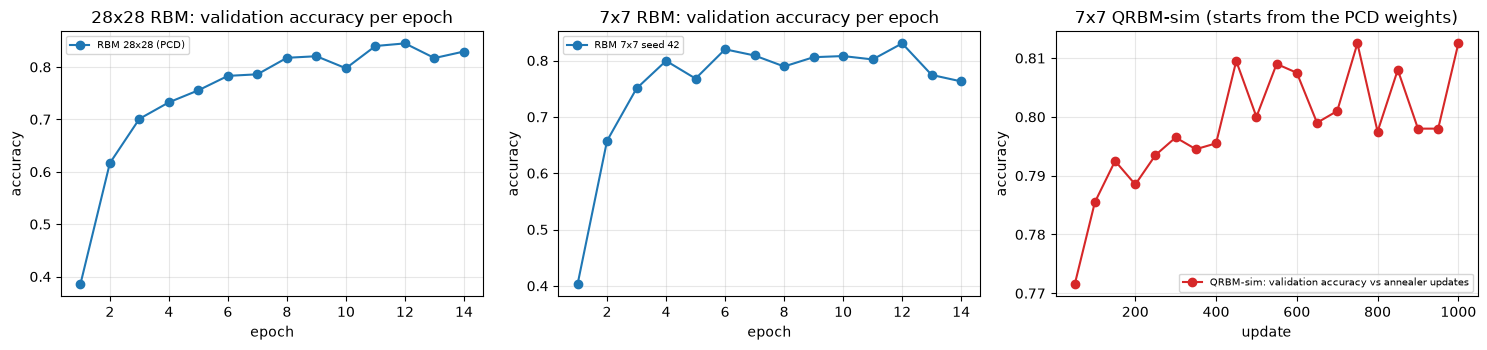

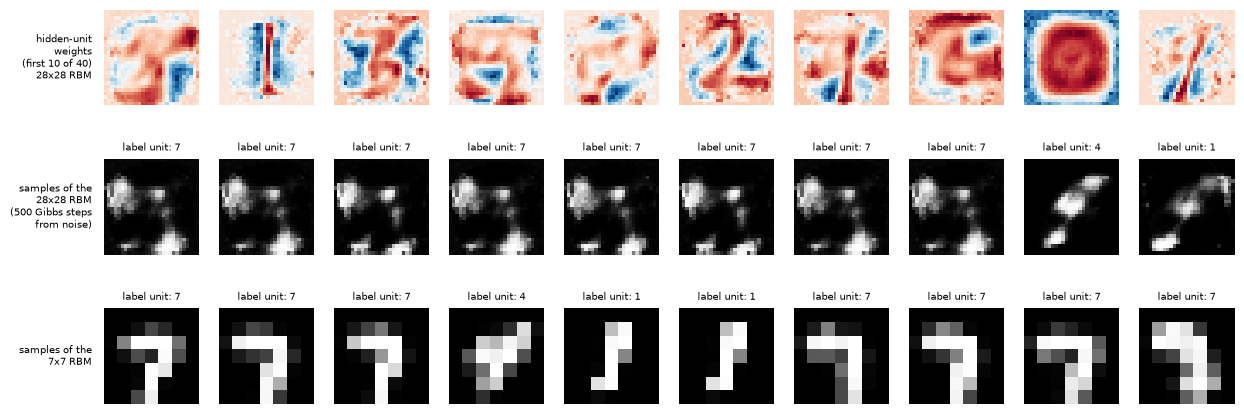

In [18]:
# What the RBMs learned: training curves, hidden-unit receptive fields, and fantasy particles drawn from the model.
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for tag in sorted({l[0] for l in LOGS if l[0].startswith(("RBM", "CNN", "Adversarial", "MLP"))}):
    pts = [(l[1], l[2]) for l in LOGS if l[0] == tag]
    if tag.startswith("RBM 28"): axs[0].plot(*zip(*pts), "o-", label=tag)
    elif tag.startswith("RBM 7x7"): axs[1].plot(*zip(*pts), "o-", label=tag)
qpts = [(l[1], l[2]) for l in LOGS if l[0].startswith("QRBM-sim")]
if qpts: axs[2].plot(*zip(*qpts), "o-", color="C3", label="QRBM-sim: validation accuracy vs annealer updates")
axs[0].set_title("28x28 RBM: validation accuracy per epoch"); axs[0].set_xlabel("epoch"); axs[1].set_title("7x7 RBM: validation accuracy per epoch"); axs[1].set_xlabel("epoch")
axs[2].set_title("7x7 QRBM-sim (starts from the PCD weights)"); axs[2].set_xlabel("update")
for a in axs: a.set_ylabel("accuracy"); a.legend(fontsize=7); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

def fantasy(m, side, n=20, k=500, seed=SEED):
    gen = torch.Generator().manual_seed(seed); v = bern(torch.full((n, m.nx + 10), 0.5), gen)
    with torch.no_grad():
        for _ in range(k):
            h = bern(torch.sigmoid(m.c + v @ m.W), gen); v = bern(torch.sigmoid(m.b + h @ m.W.T), gen)
        pv = torch.sigmoid(m.b + torch.sigmoid(m.c + v @ m.W) @ m.W.T)
    return pv[:, :m.nx], pv[:, m.nx:].argmax(1)
fig, axs = plt.subplots(3, 10, figsize=(13, 4.4))
W28 = MODELS[28]["RBM"]["f"].W[:784]
for j in range(10): axs[0, j].imshow(W28[:, j].detach().reshape(28, 28).numpy(), cmap="RdBu_r"); axs[0, j].axis("off")
axs[0, 0].text(-0.12, 0.5, "hidden-unit\nweights\n(first 10 of 40)\n28x28 RBM", transform=axs[0, 0].transAxes, ha="right", va="center", fontsize=7)
fp, fl = fantasy(MODELS[28]["RBM"]["f"], 28)
for j in range(10): axs[1, j].imshow(fp[j].reshape(28, 28).numpy(), cmap="gray"); axs[1, j].set_title(f"label unit: {fl[j].item()}", fontsize=7); axs[1, j].axis("off")
axs[1, 0].text(-0.12, 0.5, "samples of the\n28x28 RBM\n(500 Gibbs steps\nfrom noise)", transform=axs[1, 0].transAxes, ha="right", va="center", fontsize=7)
fp7, fl7 = fantasy(MODELS[7]["RBM"]["f"], 7)
for j in range(10): axs[2, j].imshow(fp7[j].reshape(7, 7).numpy(), cmap="gray"); axs[2, j].set_title(f"label unit: {fl7[j].item()}", fontsize=7); axs[2, j].axis("off")
axs[2, 0].text(-0.12, 0.5, "samples of the\n7x7 RBM", transform=axs[2, 0].transAxes, ha="right", va="center", fontsize=7)
fig.subplots_adjust(left=0.12, right=0.99, top=0.95, bottom=0.02, hspace=0.35); plt.show()

## 7. Results: the paper's Tables 1 and 2 re-run

**P1 (paper protocol).** The defence is applied to the data, the attack is built against the classifier on the defended test images, and the classifier then sees the adversarial image directly.
**P2 (adaptive).** The attacker perturbs the raw image and the whole pipeline (defence + classifier) sees the result; BPDA supplies the gradient through squeezing and smoothing.
Adversarial training, the MLP-40 twin, the RBM and the QRBM-sim have no pre-processing, so P1 and P2 are identical for them. Accuracy is measured over all attacked test images.

In [19]:
# ---------------- evaluation: the paper's protocol (P1) and the adaptive protocol (P2) ----------------
def run_attacks(f_att, f_eval, x, y, eps_l2, gen=None):
    """Craft FGSM / DeepFool / C&W adversarials against f_att and score them with f_eval. Accuracy is over ALL attacked images
    (a clean mistake counts as an error), as foolbox robust accuracy. L2 attacks are clipped to the L2 ball eps_l2."""
    out = {}
    out["FGSM"] = acc(f_eval, fgsm(f_att, x, y, EPS_LINF), y)
    ok0 = (f_eval(x).argmax(1) == y).detach()
    for nm, fn in (("DeepFool", deepfool), ("CarliniWagner", carlini_wagner_l2)):
        adv = fn(f_att, x, y)
        out[nm] = acc(f_eval, clip_l2(x, adv, eps_l2), y)
        d = (adv - x).norm(dim=1); succ = ok0 & (f_eval(adv).argmax(1) != y).detach()
        out[nm + " median min-L2"] = d[succ].median().item() if succ.any() else float("nan")
        out[nm + " success@inf"] = succ.float().sum().item() / max(ok0.float().sum().item(), 1)
    return out

def evaluate_all(side):
    eps_l2 = EPS_L2_28 if side == 28 else EPS_L2_7; rows = []
    X, Y, Xa, Ya = DS[side]["Xte"], DS[side]["yte"], DS[side]["Xatt"], DS[side]["yatt"]
    for name, M in MODELS[side].items():
        t0 = time.time(); f, D = M["f"], M["D"]
        f_pipe = (lambda x, f=f, D=D: f(D(x))) if D is not None else f
        clean = acc(f_pipe, X, Y); clean_att = acc(f_pipe, Xa, Ya)
        # P1: the defence is applied to the data, the attacks are then built against the classifier on the defended images (paper, Sec. 4)
        xin = D(Xa) if D is not None else Xa
        p1 = run_attacks(f, f, xin, Ya, eps_l2)
        # P2: adaptive attacker: attacks the raw image through the whole pipeline; non-differentiable defences are handled with BPDA
        if D is not None:
            f_bp = lambda x, f=f, D=D: f(bpda(D)(x))
            p2 = run_attacks(f_bp, f_pipe, Xa, Ya, eps_l2)
        else:
            p2 = p1
        rows.append(dict(dataset=f"{side}x{side}", defence=name, clean_acc=clean, clean_acc_attacked_subset=clean_att,
                         **{f"P1 {k}": v for k, v in p1.items()}, **{f"P2 {k}": v for k, v in p2.items()}, attack_secs=time.time() - t0))
        print(f"  {side}x{side} {name:<20s} clean {clean:.3f} | P1 FGSM {p1['FGSM']:.3f} DF {p1['DeepFool']:.3f} CW {p1['CarliniWagner']:.3f} | "
              f"P2 FGSM {p2['FGSM']:.3f} DF {p2['DeepFool']:.3f} CW {p2['CarliniWagner']:.3f}   ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)

In [20]:
set_seed(SEED)
RES = {side: evaluate_all(side) for side in (28, 7)}
RES_ALL = pd.concat(RES.values(), ignore_index=True)
show = RES_ALL[["dataset", "defence", "clean_acc", "P1 FGSM", "P1 DeepFool", "P1 CarliniWagner", "P2 FGSM", "P2 DeepFool", "P2 CarliniWagner"]].copy()
for c_ in show.columns[2:]: show[c_] = (100 * show[c_]).round(2)
print("\nAccuracy in % after each attack (P1 = paper protocol, P2 = adaptive / BPDA protocol; identical for models without pre-processing)")
print(show.to_string(index=False))

  28x28 CNN (undefended)     clean 0.927 | P1 FGSM 0.013 DF 0.223 CW 0.240 | P2 FGSM 0.013 DF 0.223 CW 0.240   (23s)


  28x28 Adv. training        clean 0.938 | P1 FGSM 0.387 DF 0.570 CW 0.527 | P2 FGSM 0.387 DF 0.570 CW 0.527   (28s)


  28x28 Feat. squeezing      clean 0.923 | P1 FGSM 0.033 DF 0.347 CW 0.330 | P2 FGSM 0.660 DF 0.730 CW 0.723   (66s)


  28x28 Spatial smoothing    clean 0.917 | P1 FGSM 0.010 DF 0.160 CW 0.140 | P2 FGSM 0.010 DF 0.250 CW 0.263   (81s)


  28x28 MLP-40 (backprop)    clean 0.933 | P1 FGSM 0.000 DF 0.040 CW 0.007 | P2 FGSM 0.000 DF 0.040 CW 0.007   (2s)


...

  7x7 Feat. squeezing      clean 0.787 | P1 FGSM 0.037 DF 0.460 CW 0.480 | P2 FGSM 0.767 DF 0.767 CW 0.767   (8s)


  7x7 Spatial smoothing    clean 0.616 | P1 FGSM 0.013 DF 0.203 CW 0.213 | P2 FGSM 0.273 DF 0.533 CW 0.433   (9s)


  7x7 MLP-40 (backprop)    clean 0.815 | P1 FGSM 0.017 DF 0.250 CW 0.287 | P2 FGSM 0.017 DF 0.250 CW 0.287   (0s)


  7x7 RBM                  clean 0.717 | P1 FGSM 0.067 DF 0.280 CW 0.273 | P2 FGSM 0.067 DF 0.280 CW 0.273   (2s)


  7x7 QRBM-sim             clean 0.760 | P1 FGSM 0.187 DF 0.307 CW 0.340 | P2 FGSM 0.187 DF 0.307 CW 0.340   (2s)

Accuracy in % after each attack (P1 = paper protocol, P2 = adaptive / BPDA protocol; identical for models without pre-processing)
dataset           defence  clean_acc  P1 FGSM  P1 DeepFool  P1 CarliniWagner  P2 FGSM  P2 DeepFool  P2 CarliniWagner
  28x28  CNN (undefended)      92.72     1.33        22.33             24.00     1.33        22.33             24.00
  28x28     Adv. training      93.82    38.67        57.00             52.67    38.67        57.00             52.67
  28x28   Feat. squeezing      92.29     3.33        34.67             33.00    66.00        73.00             72.33
  28x28 Spatial smoothing      91.68     1.00        16.00             14.00     1.00        25.00             26.33
  28x28 MLP-40 (backprop)      93.35     0.00         4.00              0.67     0.00         4.00              0.67
  28x28               RBM      77.42    14.00        

### How far away is the nearest adversarial example?

An accuracy at a fixed budget depends on the budget, which the paper does not report. A budget-free view is the size of the smallest perturbation DeepFool / Carlini-Wagner can find (L2 norm of the
perturbation, only for images the model classified correctly). A *larger* median distance means a more robust model; "success" is the share of correctly classified images for which an adversarial example was found at all.

In [21]:
# How far is the nearest adversarial example? Unbounded (minimal-norm) DeepFool / C&W perturbations, on the images each model classified correctly.
tab = RES_ALL[["dataset", "defence", "P2 DeepFool success@inf", "P2 DeepFool median min-L2", "P2 CarliniWagner success@inf", "P2 CarliniWagner median min-L2"]].copy()
tab.columns = ["dataset", "model", "DeepFool success", "DeepFool median L2", "C&W success", "C&W median L2"]
print(tab.round(3).to_string(index=False))
print("\nBudgets used for the accuracy numbers above: FGSM L-inf =", EPS_LINF, "| DeepFool and C&W L2 =", EPS_L2_28, "(28x28),", round(EPS_L2_7, 3), "(7x7)")

dataset             model  DeepFool success  DeepFool median L2  C&W success  C&W median L2
  28x28  CNN (undefended)             1.000               1.507        1.000          1.501
  28x28     Adv. training             1.000               2.388        1.000          2.193
  28x28   Feat. squeezing             0.975               2.837        1.000          3.082
  28x28 Spatial smoothing             1.000               1.595        1.000          1.583
  28x28 MLP-40 (backprop)             1.000               0.757        1.000          0.741
  28x28               RBM             0.895               1.466        0.838          0.750
    7x7  CNN (undefended)             1.000               0.578        1.000          0.620
    7x7     Adv. training             1.000               0.708        1.000          0.748
    7x7   Feat. squeezing             0.970               1.212        1.000          0.958
    7x7 Spatial smoothing             0.614               0.782        1.000    

### The tables as figures, adversarial images and confusion matrices

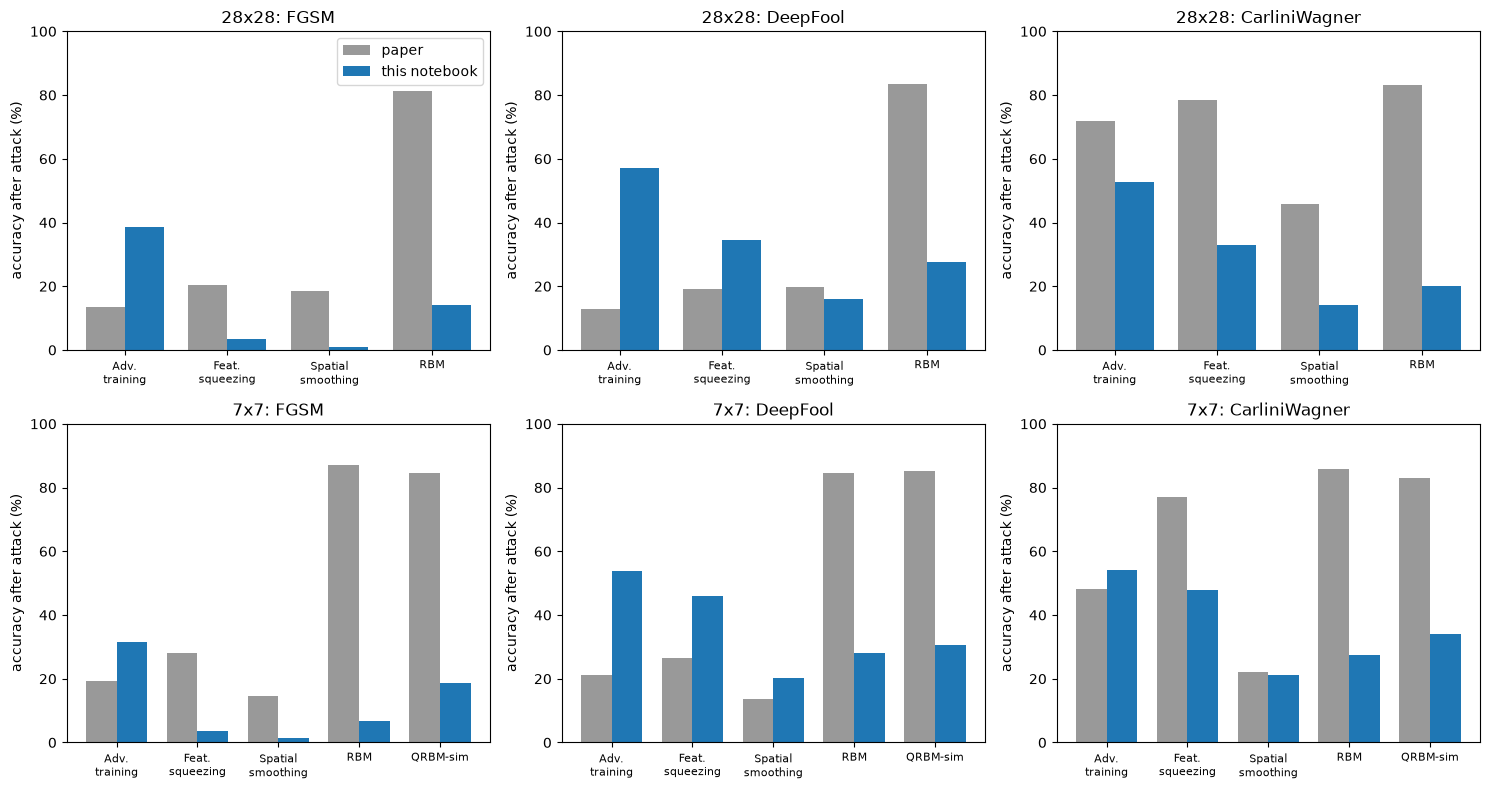

In [22]:
# Re-draw the paper's Tables 1 and 2 as grouped bars (paper vs this notebook, paper protocol P1).
PAPER = {  # accuracy in % after the attack; paper Table 1 (28x28 grey) and Table 2 (7x7 binary)
    28: {"Adv. training": [13.39, 12.80, 72.00], "Feat. squeezing": [20.24, 19.10, 78.54], "Spatial smoothing": [18.54, 19.70, 45.80], "RBM": [81.18, 83.36, 83.16]},
    7:  {"Adv. training": [19.36, 21.03, 48.24], "Feat. squeezing": [28.03, 26.64, 77.15], "Spatial smoothing": [14.74, 13.66, 22.00], "RBM": [87.15, 84.50, 85.71], "QRBM-sim": [84.49, 85.18, 82.92]},
}
ATT = ["FGSM", "DeepFool", "CarliniWagner"]
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for r, side in enumerate((28, 7)):
    df = RES[side].set_index("defence")
    for c, a in enumerate(ATT):
        ax = axs[r, c]; names = list(PAPER[side]); x = np.arange(len(names)); w = 0.38
        ax.bar(x - w / 2, [PAPER[side][n][c] for n in names], w, label="paper", color="#999999")
        ax.bar(x + w / 2, [100 * df.loc[n, f"P1 {a}"] for n in names], w, label="this notebook", color="#1f77b4")
        ax.set_xticks(x); ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=8); ax.set_ylim(0, 100); ax.set_title(f"{side}x{side}: {a}"); ax.set_ylabel("accuracy after attack (%)")
        if r == 0 and c == 0: ax.legend()
plt.tight_layout(); plt.show()

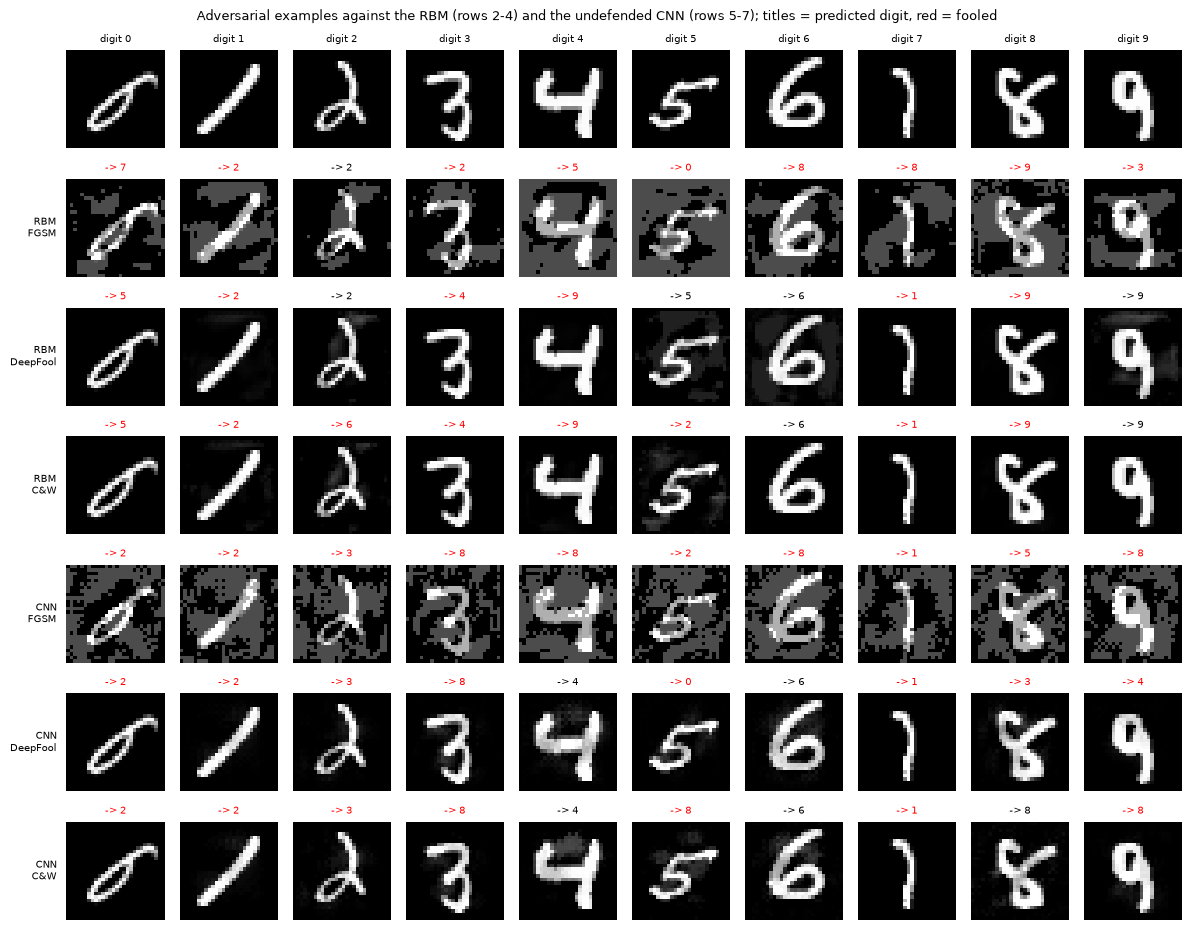

In [23]:
# Adversarial examples crafted against the RBM and against the undefended CNN (28x28), one test image per digit.
sel = [int((DS[28]["yatt"] == d).nonzero()[0]) for d in range(10)]
fig, axs = plt.subplots(7, 10, figsize=(12, 9.5))
rows = [("clean", None, None)]
for nm in ("RBM", "CNN (undefended)"):
    f = MODELS[28][nm]["f"]; x = DS[28]["Xatt"][sel]; y = DS[28]["yatt"][sel]
    advs = [("FGSM", fgsm(f, x, y, EPS_LINF)), ("DeepFool", clip_l2(x, deepfool(f, x, y), EPS_L2_28)), ("C&W", clip_l2(x, carlini_wagner_l2(f, x, y), EPS_L2_28))]
    if nm == "RBM":
        for j in range(10): axs[0, j].imshow(x[j].view(28, 28), cmap="gray", vmin=0, vmax=1); axs[0, j].axis("off"); axs[0, j].set_title(f"digit {y[j].item()}", fontsize=7)
    for ri, (an, xa) in enumerate(advs):
        row = 1 + ri + (0 if nm == "RBM" else 3)
        for j in range(10):
            axs[row, j].imshow(xa[j].view(28, 28), cmap="gray", vmin=0, vmax=1); axs[row, j].axis("off")
            axs[row, j].set_title(f"-> {f(xa[j:j+1]).argmax(1).item()}", fontsize=7, color="k" if f(xa[j:j+1]).argmax(1).item() == y[j].item() else "r")
        axs[row, 0].text(-0.1, 0.5, f"{nm.split(' ')[0]}\n{an}", transform=axs[row, 0].transAxes, ha="right", va="center", fontsize=7)
plt.suptitle("Adversarial examples against the RBM (rows 2-4) and the undefended CNN (rows 5-7); titles = predicted digit, red = fooled", fontsize=9)
plt.tight_layout(); plt.show()

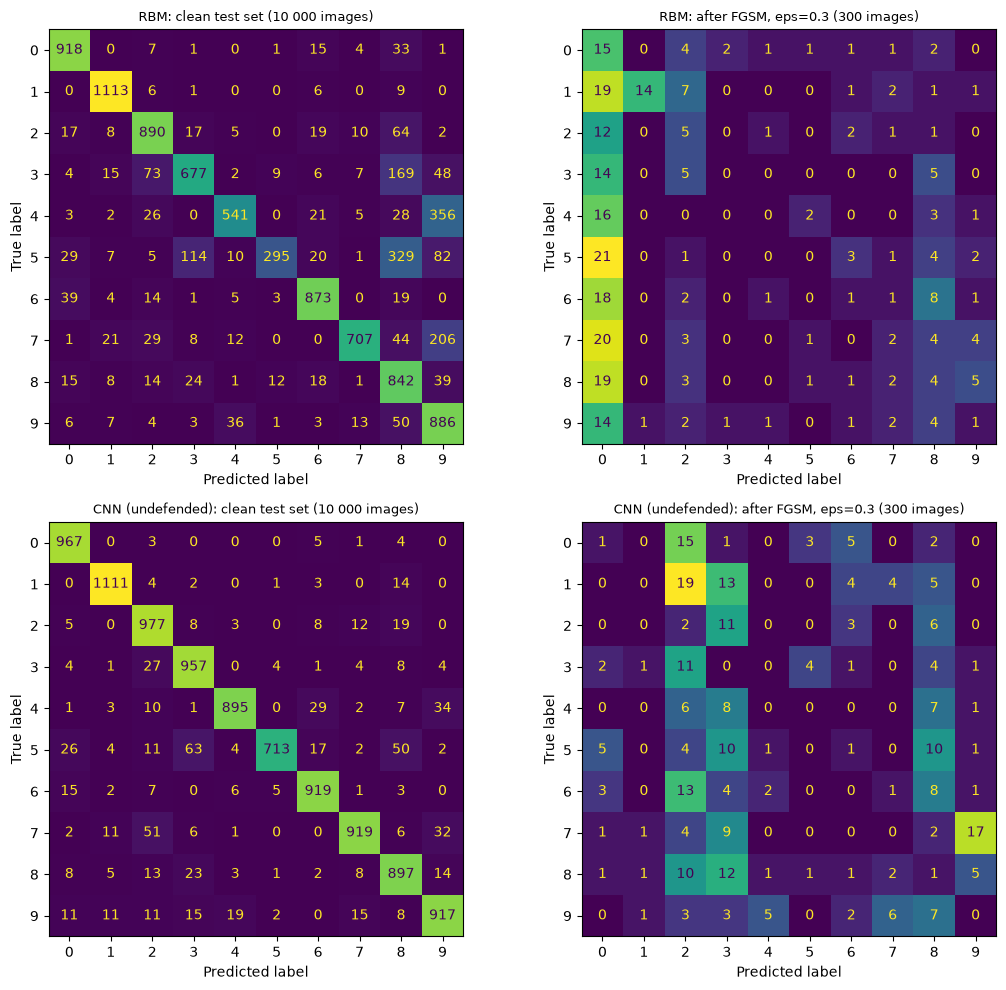

In [24]:
# Confusion matrices (10 digits, rows = true digit) of the 28x28 RBM and of the undefended CNN: clean test set and under FGSM (attacked subset).
fig, axs = plt.subplots(2, 2, figsize=(11, 10))
for r_, nm in enumerate(("RBM", "CNN (undefended)")):
    f = MODELS[28][nm]["f"]
    with torch.no_grad(): pc = f(DS[28]["Xte"]).argmax(1).numpy()
    ConfusionMatrixDisplay(confusion_matrix(DS[28]["yte"].numpy(), pc), display_labels=range(10)).plot(ax=axs[r_, 0], colorbar=False, values_format="d")
    axs[r_, 0].set_title(f"{nm}: clean test set (10 000 images)", fontsize=9)
    xa = fgsm(f, DS[28]["Xatt"], DS[28]["yatt"], EPS_LINF)
    with torch.no_grad(): pa = f(xa).argmax(1).numpy()
    ConfusionMatrixDisplay(confusion_matrix(DS[28]["yatt"].numpy(), pa, labels=range(10)), display_labels=range(10)).plot(ax=axs[r_, 1], colorbar=False, values_format="d")
    axs[r_, 1].set_title(f"{nm}: after FGSM, eps={EPS_LINF} ({N_ATTACK} images)", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Adaptive attacks and gradient-masking checks (not in the paper)

A good number in a robustness table can come from an attack that does not work well, not from a model that is hard to fool. The usual tell-tale signs (Athalye et al. 2018, Carlini et al. 2019) are tested for every model:
1. an iterated attack (PGD) is *weaker* than one-step FGSM;
2. random noise of the same size does *more* damage than the gradient attack;
3. a black-box attack (SPSA, only forward passes through the whole pipeline) beats the white-box attacks;
4. accuracy does not fall to about zero when the budget is unbounded (eps = 1 can turn any image into any other);
5. accuracy does not fall monotonically as the budget grows;
6. a single-step attack (FGSM) is much weaker than PGD, i.e. single-step numbers overestimate robustness (the classical symptom of FGSM-based adversarial training);
7. PGD with a *margin* loss (largest wrong logit minus true logit) is stronger than PGD with the cross-entropy loss, i.e. the softmax saturates and the cross-entropy gradient vanishes.
Also reported: adversarials crafted on the undefended CNN and transferred to every other model, and `worst_case` = share of images that survive FGSM, both PGD variants and SPSA at once. Flags are heuristics, not proofs.

What the stored run shows (read the tables after the code cell): **adversarial training** is flagged by check 6 (FGSM 39 % vs PGD 4 % on 28x28); **spatial smoothing** on 7x7 is flagged by check 3 (identity-BPDA is a poor
stand-in for a median filter, so the black-box attack does better); **feature squeezing** keeps its clean accuracy up to eps below 0.5 because 1-bit rounding removes any perturbation smaller than 0.5 - this is exact, not
masking, but the BPDA attacker cannot exploit the threshold, and the budget sweep shows the defence collapsing for eps of 0.5 or more; **the 28x28 RBM is flagged by the check on softmax saturation**: PGD with a margin loss (1.7 %) is stronger than PGD with the cross-entropy loss (5.3 %), and at eps = 1 the cross-entropy attack leaves 9 % of the images unflipped
while the margin version leaves 1.3 % (an optimal attacker reaches 0). The RBM logits are negative free energies and large, so the softmax saturates and the cross-entropy gradient vanishes on confidently classified images - a mild, attack-side form of gradient
masking that makes cross-entropy attacks (FGSM, PGD, SPSA) look weaker than they are. With the margin loss the RBM is as breakable as the other models; the 7x7 RBM and QRBM-sim are not flagged. A second observation the checks do not flag: uniform random
sign noise of size 0.3 alone drops the 28x28 RBM to 13 % while the CNN keeps 79 %.

In [25]:
# ---------------- adaptive attacks and gradient-masking diagnostics ----------------
# A defence whose number looks good only because the attacker's gradients are useless ("gradient masking", Athalye et al. 2018) shows
#   (1) a single-step attack that beats the iterative attack,  (2) a random-noise attack that beats the gradient attack,
#   (3) a black-box attack that beats the white-box one,       (4) accuracy that does not fall to ~0 when the budget is unbounded,
#   (5) accuracy that does not fall monotonically with the budget.   Each check is run for every model below (P2 = adaptive, BPDA for pre-processing).
def pipeline(M):
    f, D = M["f"], M["D"]
    return (lambda x: f(D(x))) if D is not None else f, ((lambda x: f(bpda(D)(x))) if D is not None else f)

def masking_report(side):
    Xa, Ya = DS[side]["Xatt"], DS[side]["yatt"]; gen = torch.Generator().manual_seed(SEED); rows = []; curves = {}; mcurves = {}; fcurves = {}
    cnn_plain = MODELS[side]["CNN (undefended)"]["f"]
    x_transfer = pgd_linf(cnn_plain, Xa, Ya, EPS_LINF, gen=gen)            # adversarials crafted on the undefended CNN only
    for name, M in MODELS[side].items():
        f_eval, f_att = pipeline(M); t0 = time.time()
        def ok(x):
            with torch.no_grad(): return f_eval(x).argmax(1) == Ya
        x_f = fgsm(f_att, Xa, Ya, EPS_LINF); x_p = pgd_linf(f_att, Xa, Ya, EPS_LINF, gen=gen); x_pm = pgd_linf(f_att, Xa, Ya, EPS_LINF, gen=gen, loss="margin")
        x_s = spsa_linf(f_eval, Xa, Ya, EPS_LINF, gen=gen)                    # SPSA: black-box, only forward passes through the whole pipeline
        x_n = (Xa + EPS_LINF * (torch.randint(0, 2, Xa.shape, generator=gen) * 2 - 1).float()).clamp(0, 1)
        a_fgsm, a_pgd, a_pgdm, a_spsa, a_noise, a_trans = (ok(x).float().mean().item() for x in (x_f, x_p, x_pm, x_s, x_n, x_transfer))
        worst = (ok(x_f) & ok(x_p) & ok(x_pm) & ok(x_s)).float().mean().item()   # robust only if it survives all four L-infinity attacks
        curve = [acc(f_eval, pgd_linf(f_att, Xa, Ya, e, steps=PGD_SWEEP_STEPS, gen=gen) if e > 0 else Xa, Ya) for e in EPS_SWEEP]
        mcurve = [acc(f_eval, pgd_linf(f_att, Xa, Ya, e, steps=PGD_SWEEP_STEPS, gen=gen, loss="margin") if e > 0 else Xa, Ya) for e in EPS_SWEEP]
        fcurve = [acc(f_eval, fgsm(f_att, Xa, Ya, e) if e > 0 else Xa, Ya) for e in EPS_SWEEP]
        curves[name] = curve; mcurves[name] = mcurve; fcurves[name] = fcurve
        best = [min(a, b) for a, b in zip(curve, mcurve)]                    # the stronger of the two PGD variants at every budget
        mono = all(best[k + 1] <= best[k] + 0.03 for k in range(len(best) - 1))
        flags = []
        if a_pgd > a_fgsm + 0.02: flags.append("PGD weaker than FGSM")
        if a_fgsm > min(a_pgd, a_pgdm) + 0.20: flags.append("single-step FGSM greatly overestimates robustness (PGD much lower)")
        if a_pgdm < a_pgd - 0.03: flags.append("margin-loss PGD stronger than cross-entropy PGD (softmax saturation)")
        if a_noise < min(a_pgd, a_pgdm) - 0.02: flags.append("noise beats PGD")
        if a_spsa < min(a_pgd, a_pgdm) - 0.05: flags.append("black-box beats white-box")
        if best[-1] > 0.03: flags.append(f"acc {100 * best[-1]:.0f}% at eps=1 under the stronger PGD")
        if not mono: flags.append("non-monotone in eps")
        rows.append(dict(dataset=f"{side}x{side}", model=name, FGSM=a_fgsm, PGD_CE=a_pgd, PGD_margin=a_pgdm, SPSA_blackbox=a_spsa, worst_case=worst, random_noise=a_noise,
                         transfer_from_CNN=a_trans, acc_at_eps1_CE=curve[-1], acc_at_eps1_margin=mcurve[-1], masking_flags="; ".join(flags) or "none"))
        print(f"  {side}x{side} {name:<20s} FGSM {a_fgsm:.3f} PGD-CE {a_pgd:.3f} PGD-margin {a_pgdm:.3f} SPSA {a_spsa:.3f} worst {worst:.3f} | noise {a_noise:.3f} transfer {a_trans:.3f} | eps=1: CE {curve[-1]:.3f} margin {mcurve[-1]:.3f} | flags: {rows[-1]['masking_flags']}  ({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows), curves, mcurves, fcurves

MASK, CURVES, MCURVES, FCURVES = {}, {}, {}, {}
for side in (28, 7):
    MASK[side], CURVES[side], MCURVES[side], FCURVES[side] = masking_report(side)
MASK_ALL = pd.concat(MASK.values(), ignore_index=True)
cols = ["dataset", "model", "FGSM", "PGD_CE", "PGD_margin", "SPSA_blackbox", "worst_case", "random_noise", "transfer_from_CNN"]
print("\nAccuracy in % at L-inf eps =", EPS_LINF, "(worst_case = share of images that survive FGSM, both PGD variants and SPSA at once)")
print((MASK_ALL[cols].assign(**{c_: (100 * MASK_ALL[c_]).round(1) for c_ in cols[2:]})).to_string(index=False))
print("\nGradient-masking flags:"); print(MASK_ALL[["dataset", "model", "masking_flags"]].to_string(index=False))

  28x28 CNN (undefended)     FGSM 0.013 PGD-CE 0.000 PGD-margin 0.000 SPSA 0.357 worst 0.000 | noise 0.793 transfer 0.000 | eps=1: CE 0.000 margin 0.000 | flags: none  (44s)


  28x28 Adv. training        FGSM 0.387 PGD-CE 0.037 PGD-margin 0.037 SPSA 0.747 worst 0.030 | noise 0.900 transfer 0.203 | eps=1: CE 0.000 margin 0.000 | flags: single-step FGSM greatly overestimates robustness (PGD much lower)  (46s)


  28x28 Feat. squeezing      FGSM 0.660 PGD-CE 0.640 PGD-margin 0.650 SPSA 0.837 worst 0.630 | noise 0.933 transfer 0.670 | eps=1: CE 0.000 margin 0.000 | flags: none  (57s)


  28x28 Spatial smoothing    FGSM 0.010 PGD-CE 0.003 PGD-margin 0.007 SPSA 0.317 worst 0.003 | noise 0.750 transfer 0.013 | eps=1: CE 0.000 margin 0.000 | flags: none  (161s)


  28x28 MLP-40 (backprop)    FGSM 0.000 PGD-CE 0.000 PGD-margin 0.000 SPSA 0.083 worst 0.000 | noise 0.497 transfer 0.000 | eps=1: CE 0.000 margin 0.000 | flags: none  (17s)


...

  7x7 Spatial smoothing    FGSM 0.273 PGD-CE 0.153 PGD-margin 0.147 SPSA 0.080 worst 0.057 | noise 0.510 transfer 0.093 | eps=1: CE 0.000 margin 0.003 | flags: black-box beats white-box  (30s)


  7x7 MLP-40 (backprop)    FGSM 0.017 PGD-CE 0.000 PGD-margin 0.003 SPSA 0.020 worst 0.000 | noise 0.533 transfer 0.020 | eps=1: CE 0.000 margin 0.000 | flags: none  (2s)


  7x7 RBM                  FGSM 0.067 PGD-CE 0.010 PGD-margin 0.017 SPSA 0.033 worst 0.003 | noise 0.370 transfer 0.090 | eps=1: CE 0.000 margin 0.000 | flags: none  (7s)


  7x7 QRBM-sim             FGSM 0.187 PGD-CE 0.017 PGD-margin 0.007 SPSA 0.093 worst 0.007 | noise 0.467 transfer 0.113 | eps=1: CE 0.000 margin 0.000 | flags: none  (7s)

Accuracy in % at L-inf eps = 0.3 (worst_case = share of images that survive FGSM, both PGD variants and SPSA at once)


dataset             model  FGSM  PGD_CE  PGD_margin  SPSA_blackbox  worst_case  random_noise  transfer_from_CNN
  28x28  CNN (undefended)   1.3     0.0         0.0           35.7         0.0          79.3                0.0
  28x28     Adv. training  38.7     3.7         3.7           74.7         3.0          90.0               20.3
  28x28   Feat. squeezing  66.0    64.0        65.0           83.7        63.0          93.3               67.0
  28x28 Spatial smoothing   1.0     0.3         0.7           31.7         0.3          75.0                1.3
  28x28 MLP-40 (backprop)   0.0     0.0         0.0            8.3         0.0          49.7                0.0
  28x28               RBM  14.0     5.3         1.7            9.7         1.3          12.7               12.0
    7x7  CNN (undefended)   3.7     1.3         3.3           18.3         1.0          75.0                2.0
    7x7     Adv. training  31.7    21.3        19.0           45.7        16.7          69.7            

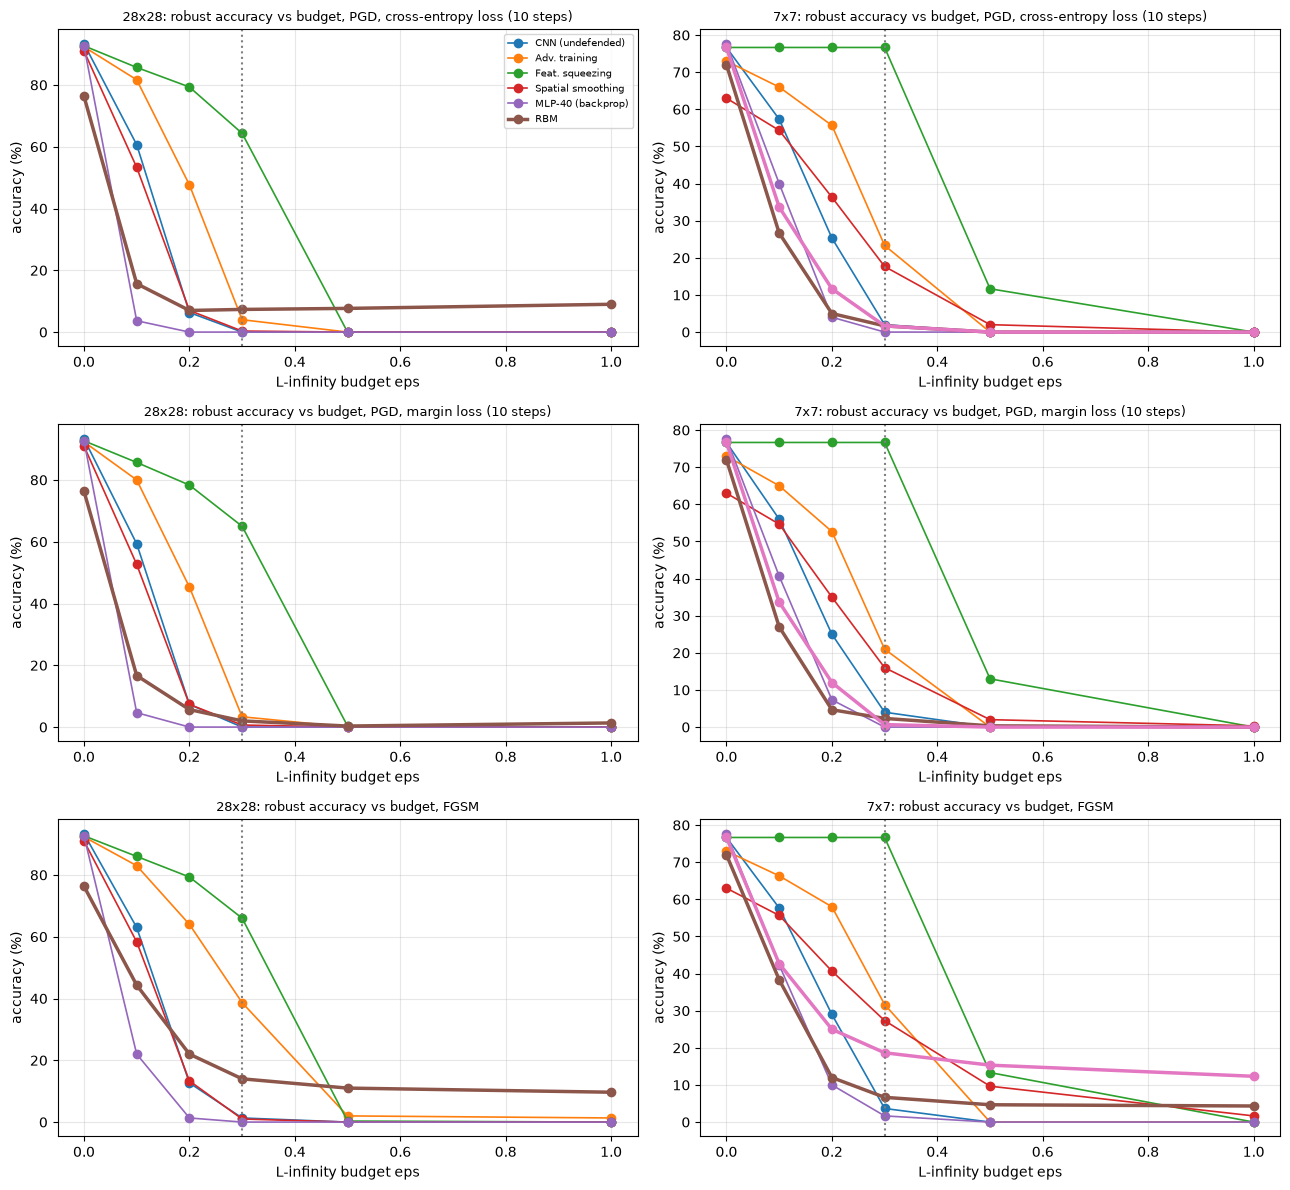

In [26]:
fig, axs = plt.subplots(3, 2, figsize=(13, 12))
for c_, side in enumerate((28, 7)):
    for r_, (CV, ttl) in enumerate(((CURVES, "PGD, cross-entropy loss (10 steps)"), (MCURVES, "PGD, margin loss (10 steps)"), (FCURVES, "FGSM"))):
        ax = axs[r_, c_]
        for name, cv in CV[side].items(): ax.plot(EPS_SWEEP, 100 * np.array(cv), "o-", label=name, lw=2.5 if "RBM" in name else 1.2)
        ax.axvline(EPS_LINF, color="gray", ls=":"); ax.set_xlabel("L-infinity budget eps"); ax.set_ylabel("accuracy (%)"); ax.set_title(f"{side}x{side}: robust accuracy vs budget, {ttl}", fontsize=9); ax.grid(alpha=.3)
axs[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Seed spread and classical baselines on the same inputs

### 9a. Several seeds on the 7x7 data

In [27]:
# Seed variability on the cheap 7x7 data: every extra seed re-trains the RBM (PCD) and the QRBM-sim from scratch and is attacked with the paper protocol.
rows = []
for si, (m, q) in enumerate(zip(RBM7, QRBM7)):
    for nm, mod in (("RBM", m), ("QRBM-sim", q)):
        Xa, Ya = DS[7]["Xatt"], DS[7]["yatt"]
        r = run_attacks(mod, mod, Xa, Ya, EPS_L2_7)
        rows.append(dict(seed=SEED + si, model=nm, clean=acc(mod, DS[7]["Xte"], DS[7]["yte"]), FGSM=r["FGSM"], DeepFool=r["DeepFool"], CarliniWagner=r["CarliniWagner"]))
S = pd.DataFrame(rows)
print((100 * S.set_index(["seed", "model"])).round(2).to_string())
agg = S.groupby("model")[["clean", "FGSM", "DeepFool", "CarliniWagner"]].agg(["mean", "std"]) * 100
print("\nmean / std over", N_SEEDS_7, "seeds (accuracy %)"); print(agg.round(2).to_string())

               clean   FGSM  DeepFool  CarliniWagner
seed model                                          
42   RBM       71.74   6.67     28.00          27.33
     QRBM-sim  75.97  18.67     30.67          34.00
43   RBM       72.34   3.67     21.33          23.67
     QRBM-sim  75.67  17.33     38.00          40.00

mean / std over 2 seeds (accuracy %)
          clean         FGSM       DeepFool       CarliniWagner      
           mean   std   mean   std     mean   std          mean   std
model                                                                
QRBM-sim  75.82  0.21  18.00  0.94    34.33  5.19          37.0  4.24
RBM       72.04  0.42   5.17  2.12    24.67  4.71          25.5  2.59


### 9b. Classical scikit-learn models on the same inputs

In [28]:
# Classical scikit-learn baselines on exactly the same inputs (7x7 binary pixels, and 28x28 pixels), attacked in a transfer (black-box) setting
# with the adversarials crafted on the undefended CNN, since these models have no input gradient.
rows = []
for side in (7, 28):
    Xs = DS[side]["Xtr"][tr_idx_clf].numpy(); Ys = DS[side]["ytr"][tr_idx_clf].numpy(); n_fit = min(len(Xs), 4000)    # CHOICE: 4 000 training images for every scikit-learn model (the RBF-SVC is slow on one thread)
    Xt, Yt = DS[side]["Xte"].numpy(), DS[side]["yte"].numpy()
    xa_t = pgd_linf(MODELS[side]["CNN (undefended)"]["f"], DS[side]["Xatt"], DS[side]["yatt"], EPS_LINF, gen=torch.Generator().manual_seed(SEED)).numpy()
    for nm, mdl in (("LogisticRegression", LogisticRegression(max_iter=200)), ("RandomForest(100)", RandomForestClassifier(100, random_state=SEED, n_jobs=1)),
                    ("SVC(rbf)", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED))):
        t0 = time.time(); mdl.fit(Xs[:n_fit], Ys[:n_fit])
        rows.append(dict(dataset=f"{side}x{side}", model=nm, fitted_on=n_fit, clean_acc=100 * (mdl.predict(Xt) == Yt).mean(),
                         transfer_PGD_eps03=100 * (mdl.predict(xa_t) == DS[side]["yatt"].numpy()).mean(), secs=time.time() - t0))
print(pd.DataFrame(rows).round(2).to_string(index=False))

dataset              model  fitted_on  clean_acc  transfer_PGD_eps03   secs
    7x7 LogisticRegression       4000      78.77                3.00   9.50
    7x7  RandomForest(100)       4000      83.76               82.67   4.48
    7x7           SVC(rbf)       4000      84.01               12.33  20.80
  28x28 LogisticRegression       4000      89.08                0.33  89.37
  28x28  RandomForest(100)       4000      93.09                4.33  16.73
  28x28           SVC(rbf)       4000      94.78                4.33 174.96


## 10. Side-by-side comparison with the paper

Verdicts use P1 (the paper's protocol), the accuracy tolerance is 2 points: "reproduced" if within 2 points, otherwise "not reached" (ours lower) or "exceeded" (ours higher).
Cells for the baseline defences compare a small CNN with the paper's fine-tuned ResNet18 and our own attack implementations with foolbox, so deviations there are expected and should not be read as a refutation.
The rows after the 27 numeric cells test the paper's qualitative claims (RBM best everywhere, QRBM on par with the RBM, the 4.62 to 72.41 point range of the abstract); two "extra check" rows report that
the paper's RBM numbers (81 % and 87 %) are *higher than the clean accuracy of this notebook's RBM* (77 % and 72 %), so no FGSM budget could ever reproduce them with our trained RBMs.

In [29]:
# ---------------- side-by-side comparison with the paper, one verdict per claim (tolerance: 2 accuracy points) ----------------
def verdict(ours, paper, tol=TOL_POINTS):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

rows = []
for side, tabno in ((28, 1), (7, 2)):
    df = RES[side].set_index("defence")
    for ai, a in enumerate(ATT):
        for nm, vals in PAPER[side].items():
            ours = 100 * df.loc[nm, f"P1 {a}"]
            rows.append(dict(claim=f"Table {tabno}: {side}x{side}, {nm}, {a}", paper_pct=vals[ai], notebook_pct=round(ours, 2),
                             difference=round(ours - vals[ai], 2), verdict=verdict(ours, vals[ai])))
cmp_tab = pd.DataFrame(rows)

# qualitative claims of the paper
q = []
for side, tabno in ((28, 1), (7, 2)):
    df = RES[side].set_index("defence"); base = ["Adv. training", "Feat. squeezing", "Spatial smoothing"]
    for a in ATT:
        best_base = max(100 * df.loc[b, f"P1 {a}"] for b in base); r = 100 * df.loc["RBM", f"P1 {a}"]
        q.append(dict(claim=f"Table {tabno}, {a}: RBM is the best defence ({side}x{side})", paper_pct="RBM best", notebook_pct=f"RBM {r:.1f} vs best baseline {best_base:.1f}",
                      difference=round(r - best_base, 2), verdict="reproduced" if r > best_base else "not reached"))
dq = RES[7].set_index("defence")
gap = max(abs(100 * (dq.loc["QRBM-sim", f"P1 {a}"] - dq.loc["RBM", f"P1 {a}"])) for a in ATT)
q.append(dict(claim="Table 2: QRBM is on par with the RBM (largest gap over the 3 attacks)", paper_pct="gap <= 2.79 pts (paper)", notebook_pct=f"gap {gap:.2f} pts (simulated annealer)",
              difference=round(gap - 2.79, 2), verdict="reproduced" if gap <= 2.79 + TOL_POINTS else "not reached"))
wins = [a for a in ATT if dq.loc["QRBM-sim", f"P1 {a}"] > dq.loc["RBM", f"P1 {a}"]]
q.append(dict(claim="Table 2: QRBM beats the RBM only under DeepFool", paper_pct="DeepFool only", notebook_pct=f"QRBM-sim better under: {wins or 'none'}",
              difference=np.nan, verdict="reproduced" if wins == ["DeepFool"] else "not reached"))
g_best, g_worst = [], []
for side in (28, 7):
    df = RES[side].set_index("defence")
    for a in ATT:
        b = [100 * df.loc[n_, f"P1 {a}"] for n_ in ["Adv. training", "Feat. squeezing", "Spatial smoothing"]]; r_ = 100 * df.loc["RBM", f"P1 {a}"]
        g_best.append(r_ - max(b)); g_worst.append(r_ - min(b))
q.append(dict(claim="Abstract: smallest gain of the RBM over the best baseline (any cell)", paper_pct=4.62, notebook_pct=round(min(g_best), 2),
              difference=round(min(g_best) - 4.62, 2), verdict=verdict(min(g_best), 4.62)))
q.append(dict(claim="Abstract: largest gain of the RBM over the worst baseline (any cell)", paper_pct=72.41, notebook_pct=round(max(g_worst), 2),
              difference=round(max(g_worst) - 72.41, 2), verdict=verdict(max(g_worst), 72.41)))
q.append(dict(claim="Clean (unattacked) accuracy of the RBM", paper_pct="not reported", notebook_pct=f"28x28 {100 * RES[28].set_index('defence').loc['RBM', 'clean_acc']:.1f}; 7x7 {100 * RES[7].set_index('defence').loc['RBM', 'clean_acc']:.1f}",
              difference=np.nan, verdict="cannot be checked"))
def eps_at(curve, target):          # FGSM budget at which a (monotone) robust-accuracy curve crosses `target` (linear interpolation)
    for i in range(len(curve) - 1):
        if curve[i] >= target >= curve[i + 1]:
            return EPS_SWEEP[i] + (EPS_SWEEP[i + 1] - EPS_SWEEP[i]) * (curve[i] - target) / max(curve[i] - curve[i + 1], 1e-9)
    return float("nan")
for side, tgt, nm in ((28, 81.18, "Table 1 (28x28)"), (7, 87.15, "Table 2 (7x7)")):
    e_ = eps_at(FCURVES[side]["RBM"], tgt / 100)
    q.append(dict(claim=f"Extra: FGSM budget at which this notebook's RBM accuracy falls to the paper's RBM value, {nm}", paper_pct=tgt, notebook_pct=f"eps = {e_:.3f}" if e_ == e_ else "never reaches that value (clean accuracy is lower)",
                  difference=np.nan, verdict="extra check (the paper does not report its budget)"))
q.append(dict(claim="Robustness of the RBM holds against an adaptive attacker (not tested in the paper)", paper_pct="not tested", notebook_pct="see gradient-masking section: PGD / eps=1 rows",
              difference=np.nan, verdict="extra check"))
cmp_all = pd.concat([cmp_tab, pd.DataFrame(q)], ignore_index=True)
pd.set_option("display.max_colwidth", 90)
print(cmp_all.to_string(index=False))
print("\nverdict counts:"); print(cmp_all["verdict"].value_counts().to_string())

                                                                                                   claim               paper_pct                                                 notebook_pct  difference                                            verdict
                                                                     Table 1: 28x28, Adv. training, FGSM                   13.39                                                        38.67       25.28                                           exceeded
                                                                   Table 1: 28x28, Feat. squeezing, FGSM                   20.24                                                         3.33      -16.91                                        not reached
                                                                 Table 1: 28x28, Spatial smoothing, FGSM                   18.54                                                          1.0      -17.54                                        

In [30]:
# The same RBM / baseline numbers under the adaptive protocol P2 (what a real attacker would get), next to the paper's numbers.
rows = []
for side in (28, 7):
    df = RES[side].set_index("defence")
    for nm in PAPER[side]:
        rows.append(dict(dataset=f"{side}x{side}", defence=nm,
                         **{f"{a} paper": PAPER[side][nm][i] for i, a in enumerate(ATT)}, **{f"{a} P1": round(100 * df.loc[nm, f"P1 {a}"], 1) for a in ATT},
                         **{f"{a} P2": round(100 * df.loc[nm, f"P2 {a}"], 1) for a in ATT}))
print(pd.DataFrame(rows).to_string(index=False))

dataset           defence  FGSM paper  DeepFool paper  CarliniWagner paper  FGSM P1  DeepFool P1  CarliniWagner P1  FGSM P2  DeepFool P2  CarliniWagner P2
  28x28     Adv. training       13.39           12.80                72.00     38.7         57.0              52.7     38.7         57.0              52.7
  28x28   Feat. squeezing       20.24           19.10                78.54      3.3         34.7              33.0     66.0         73.0              72.3
  28x28 Spatial smoothing       18.54           19.70                45.80      1.0         16.0              14.0      1.0         25.0              26.3
  28x28               RBM       81.18           83.36                83.16     14.0         27.7              20.0     14.0         27.7              20.0
    7x7     Adv. training       19.36           21.03                48.24     31.7         53.7              54.0     31.7         53.7              54.0
    7x7   Feat. squeezing       28.03           26.64                7

### Run time

In [31]:
T = pd.DataFrame([dict(dataset=f"{s}x{s}", model=n, train_seconds=round(t, 1)) for s in TRAIN_TIME for n, t in TRAIN_TIME[s].items()])
A = RES_ALL[["dataset", "defence", "attack_secs"]].rename(columns={"defence": "model", "attack_secs": "attack_seconds"}).round(1)
print(T.merge(A, on=["dataset", "model"]).to_string(index=False))
print("Total notebook wall-clock so far: %.1f min" % ((time.time() - T0) / 60))

dataset             model  train_seconds  attack_seconds
  28x28  CNN (undefended)           26.0            22.8
  28x28     Adv. training           73.7            28.3
  28x28   Feat. squeezing           25.7            65.5
  28x28 Spatial smoothing           40.3            81.1
  28x28 MLP-40 (backprop)           12.9             2.4
  28x28               RBM           55.4             7.0
    7x7  CNN (undefended)            7.6             3.3
    7x7     Adv. training           17.5             4.2
    7x7   Feat. squeezing            8.7             7.8
    7x7 Spatial smoothing            7.8             8.7
    7x7 MLP-40 (backprop)           10.0             0.5
    7x7               RBM           19.1             1.6
    7x7          QRBM-sim          113.8             2.0
Total notebook wall-clock so far: 29.1 min


## Reading the paper critically

**What the stored run shows.** (FAST_MODE, seed 42, 300 attacked test images, so each accuracy has a statistical error of about plus or minus 3 points.)
* *The headline is not reproduced.* On 28x28, RBM 14.0 / 27.7 / 20.0 % (FGSM / DeepFool / C&W) against the paper's 81.2 / 83.4 / 83.2 %; on 7x7, RBM 6.7 / 28.0 / 27.3 % and QRBM-sim 18.7 / 30.7 / 34.0 % against 87.2 / 84.5 / 85.7 % and 84.5 / 85.2 / 82.9 %. Our RBM is *not* the best defence in any attack: the FGSM-trained CNN is higher everywhere (and feature squeezing under the adaptive protocol).
* *The RBM is more robust than a back-propagation network of the same size, but only modestly.* The capacity-matched 784-40-10 MLP gets 0 / 4 / 1 % on the same three attacks, the RBM 14 / 28 / 20 %. In minimal-perturbation terms (median L2 distance to the nearest adversarial example, Carlini-Wagner) the two are equal (0.75 vs 0.74) and both are half as far as the undefended CNN (1.50); DeepFool finds a larger distance for the RBM (1.47) only because it fails on 10 % of the images (C&W fails on 16 % within our short optimisation budget). So the generative training buys some extra resistance to the particular attacks, not the large margin claimed.
* *The RBM is not robust against a proper white-box attacker.* Cross-entropy PGD leaves 5.3 %, margin-loss PGD 1.7 % and the worst case over FGSM, both PGD variants and SPSA 1.3 % (28x28; 7x7: RBM 0.3 %, QRBM-sim 0.7 %). The check on softmax saturation does flag the 28x28 RBM (cross-entropy attacks understate its vulnerability, which could by itself inflate robust accuracies obtained with a naive attack), but with the margin loss the accuracy-versus-budget curve reaches about zero.
* *The annealer stand-in does not behave like the paper's QRBM.* In the stored run the QRBM-sim is ahead of the classical RBM under all three attacks (about +12, +3 and +7 points), while the paper has it ahead only under DeepFool and within 2.8 points elsewhere. The comparison is confounded: the QRBM-sim has a higher clean accuracy (76.0 vs 71.7 %), was trained with 1 000-sample positive batches, and the PCD RBM was not trained to convergence; the two extra seeds show the RBM-to-RBM spread is of the same order as several of the gaps the paper discusses. This notebook therefore says nothing for or against a *quantum* advantage; it only shows that a thermal annealer is a workable negative-phase sampler (the test against the exact Boltzmann distribution passes).

**Weaknesses and open points of the paper itself.**
1. *Unreported experimental settings.* No attack budgets (L-infinity or L2), no number of epochs, no clean accuracy, no seeds and no error bars. DeepFool and Carlini-Wagner are minimal-perturbation attacks; their "accuracy after attack" is only defined relative to a budget or a clipping rule, which the paper does not give, so the 81-87 % of the RBM cannot be matched or refuted without guessing it.
2. *The RBM numbers are suspiciously flat.* The RBM scores 81-83 % (28x28) and 84-87 % (7x7) under three very different attacks, i.e. roughly the same value as a plausible clean accuracy. That is what one expects if the attacks hardly changed the RBM's prediction at all, for instance because the attack implementation received no useful gradient from the RBM wrapper (stochastic or detached sampling). Our own white-box attacks with exact gradients, a gradient-free SPSA attack and a PGD budget sweep all drive the RBM to a few percent (1 to 10 %, depending on the attack), so the claim of robustness against *white-box* attackers is not supported by this evidence. Cross-entropy attacks are the weakest of them because of softmax saturation (check 7), which shows one concrete way in which an attack run against an RBM can look much less effective than it is. This is a hypothesis about the paper's code, not a demonstrated fact.
3. *The evaluation protocol favours the proposal.* The pre-processing defences are applied to the data and the attack is then built on the already defended image, so the attacker never sees the defence and the classifier never re-applies it. Under that protocol feature squeezing scores 3 % in our run; if the attacker perturbs the raw image and the squeezing is applied afterwards (P2), the same model scores 66 %. Conversely the defence is only as good as the attacker is naive (BPDA with identity gradients cannot exploit the rounding threshold).
4. *Weak baselines.* A fine-tuned ResNet18 on 28x28 or 7x7 digits is an odd choice, and the FGSM-trained model of the baselines is known to overfit FGSM (in our run FGSM 39 % but PGD 4 %). A robustly trained network (PGD adversarial training) is the standard comparison and is missing.
5. *The quantum part cannot be attacked white-box.* The paper says so itself, so it is unclear how the QRBM column was attacked; the QRBM and RBM numbers differ by 0.7 to 2.8 points from a single unreplicated run.
6. *"Generative models are inherently robust" is not shown.* The explanation offered (overfitting of discriminative networks) is not tested; the capacity-matched control of this notebook (MLP-40) and the poor sample quality of the RBM both argue that any effect is small in our setting.

**Caveats of this reproduction.** Small CNN instead of ResNet18; own attack code with reduced Carlini-Wagner and DeepFool budgets; a thermal annealer instead of a quantum one; short RBM training (14 epochs, PCD batch 20, chain length 2) instead of the paper's batch 10 and chain length 50; 10 000 RBM training images; 300 attacked images; attack budgets chosen by us before looking at results; 7x7 binarisation threshold chosen on the validation split. The full-budget path was not run.

## Exercises

1. **Find the missing budget.** The paper gives no attack budget. Sweep `EPS_LINF` and `EPS_L2_28` (or reuse `EPS_SWEEP`) and find the budgets at which the *CNN-based* baselines of Table 1 are reproduced (for example adversarial training 13 % under FGSM). Do the RBM numbers of the paper then become plausible, or are they higher than the RBM's clean accuracy?
2. **Train longer.** Set `PCD_BATCH, PCD_K = 10, 50` and train the 28x28 RBM for 20 epochs on all 60 000 images. How much do clean accuracy, the fantasy samples and the PGD robust accuracy change? Does robustness grow with likelihood?
3. **A better generative classifier.** Add a discriminative term to the RBM objective (a "hybrid" RBM) or more hidden units (200). Is the RBM then more or less robust than its MLP twin of the same size?
4. **Temperature and sweeps of the annealer.** Vary `BETA_EFF` (0.5, 1, 2) and `QA_SWEEPS` (5, 20, 60) in the simulated annealer, keeping the training length fixed. The sampler check shows that 20 sweeps is close to equilibrium for small weights; does the training quality or robustness of the QRBM-sim depend on it, and does the classical RBM with the same number of updates close the gap?
5. **Stronger adaptive attacks.** (a) Replace identity-BPDA for feature squeezing by an attack that knows the 0.5 rounding threshold (flip pixels whose gradient points across the threshold). (b) Add a PGD attack in L2 and an EOT version for a stochastic classifier that samples the label by Gibbs sampling instead of using the exact free-energy rule. Which defence in Table 1 survives?